# What the counts cannot see — recorded crime as a report count

A recorded crime is not an event. It is a **report** that somebody made and a
department wrote down, and both of those are decisions. Reporting in particular
depends on whether reporting achieves anything: a person who believes nothing
will come of a call does not make it, and the offence is then not recorded,
which is not the same as its not having happened.

That gives the measurement error a direction. When enforcement withdraws,
reports fall, and recorded crime falls with them — so the error is
**correlated with the very thing one would want to study**. Estimate "what did
enforcement do to crime" with recorded crime as the outcome and the bias runs
the way that makes withdrawal look successful. It is not noise to be averaged
away; it is a term that moves with the treatment.

The inversion is the point of this notebook. If reports fail to arrive when
enforcement withdraws, **the failure is itself a measurement**: the gap between
what happens and what is written down measures the withdrawal. So this notebook
does not try to correct recorded crime. It tries to separate the two things
recorded crime is made of, and to see which quantities in this API can be
pushed to one side or the other.

**Two indices, kept apart.** An **anchored crime index**, from offences whose
reporting is compelled by something outside the police — homicide, because
there is a body and a death certificate; motor vehicle theft, because an
insurer will not pay without a police report. And a **withdrawal index**, from
quantities that exist only when police act. Neither answers the question alone;
the pair is the design, and section 8 is honest about what the pair can and
cannot carry.

**Four instruments**, one section each, after two sections of groundwork:

1. **Police-generated against victim-reported.** Nobody telephones in a
   disorderly conduct, a drug possession or a vagrancy: those counts exist only
   because an officer acted, so they measure the department. A homicide or a
   stolen car measures the world, or something closer to it.
2. **Arrests per officer** — effort per unit of capacity rather than per
   resident, which is a different question from the arrest rate and has a
   different answer.
3. **Composition drift** — the ratio of a badly-reported offence to a
   well-reported one, which moves when reporting drifts even where the levels
   are uninterpretable.
4. **The external check** — recorded homicide against death certificates, which
   no police decision touches.

Then **the trap**, which is that a proactive arrest count also moves when the
*law* changes rather than when enforcement does, and the two are
indistinguishable in the series.

Ninety-six requests in all: forty-one on the offence route, forty-eight on the
arrest route and seven staffing series. The filing rule is not redefined here —
it is [`utils/filing.py`](utils/filing.py)'s, which
[`walkthrough.ipynb`](walkthrough.ipynb) section 2 explains on homicide and
[`enforcement.ipynb`](enforcement.ipynb) section 3 extends to arrests. The
eight scopes and their colours are the walkthrough's, so a line means the same
place in all three notebooks. The plumbing is elsewhere:
[`api.ipynb`](api.ipynb), [`client.ipynb`](client.ipynb),
[`mcp.ipynb`](mcp.ipynb).

**Nothing here argues that anything caused anything**, and nothing here is a
policy argument. The subject is what can and cannot be measured. Every number
below is printed by the cell above it.

In [1]:
%reload_ext autoreload
%autoreload 2

import sys
from pathlib import Path

# Anchor on this notebook's own directory rather than on the working directory:
# VS Code can root a notebook at the workspace folder instead of at the file,
# and then a relative "../" resolves somewhere else entirely and the imports
# below fail with ModuleNotFoundError.
_here = Path.cwd()
_FBI = _here if (_here / "utils" / "mcp.py").exists() else _here / "notebooks" / "fbi"
for _path in (str(_FBI), str(_FBI.parents[1])):      # notebooks/fbi, then the meida root
    if _path not in sys.path:
        sys.path.insert(0, _path)

import asyncio
import json
import textwrap
import time
from datetime import datetime
from typing import Any, Callable, Sequence

import numpy
from matplotlib import pyplot
# Matplotlib accepts a datetime on an axis and converts it with this same
# function; calling it here keeps the type checker's account of the call
# honest, since the stubs type these parameters as floats.
from matplotlib.dates import date2num
from matplotlib.ticker import FuncFormatter, LogLocator, NullFormatter
from numpy.typing import NDArray

from clients.fbi import ARREST_CODES_FOR, ARREST_OFFENSES, OFFENSES
from lib import config
from utils.filing import (Payload, arrest_unreadable, context, monthly, stamp_source,
                          trailing_sum, unreadable)
from utils.mcp import StaleServerError, call_tool as _call_tool

pyplot.style.use(config.glyfish_style)

#: The walkthrough's eight scopes, with the walkthrough's colours. Seven city
#: departments and the nation they sit in; the cities are not a sample of
#: anything, and section 8 says what that costs.
SCOPES: dict[str, dict[str, Any]] = {
    "national":  {"name": "United States", "short": "US",   "colour": "0.45"},
    "NY0303000": {"name": "New York City", "short": "NYC",  "colour": "#0067C4"},
    "DCMPD0000": {"name": "Washington",    "short": "DC",   "colour": "#FF9500"},
    "CA0194200": {"name": "Los Angeles",   "short": "LA",   "colour": "#5600C9"},
    "CA0380100": {"name": "San Francisco", "short": "SF",   "colour": "#AC9C00"},
    "CA0010900": {"name": "Oakland",       "short": "Oak",  "colour": "#008A3E"},
    "CA0431300": {"name": "San Jose",      "short": "SJ",   "colour": "#C4005E"},
    "TN0190100": {"name": "Nashville",     "short": "Nash", "colour": "#AC6500"},
}
CITIES = [scope for scope in SCOPES if scope != "national"]
CALIFORNIA = ("CA0194200", "CA0380100", "CA0010900", "CA0431300")

#: The offence route, at all eight scopes. Burglary is taken nationally only --
#: it is wanted for the arrests-per-offence ladder in section 2 and for nothing
#: that needs a city -- and those seven calls buy driving under the influence
#: at agency scope instead, which section 3 needs and could not otherwise have.
WIDE_OFFENCES = ("homicide", "motor-vehicle-theft", "larceny", "robbery",
                 "aggravated-assault")
NARROW_OFFENCES = ("burglary",)

#: The arrest codes at all eight scopes. 'all' because a code is only readable
#: as a share of something; 260, 290 and 300 because they are police-generated;
#: 158 because its legal status changed inside the window, which is section 7.
WIDE_CODES = ("all", "260", "290", "300", "158")

#: Nationally only. 11 to 90 are the six codes that have an offence series to be
#: divided by, which is section 2's ladder; 230 and 330 widen the proactive set
#: where the budget will not stretch to eight scopes.
NARROW_CODES = ("11", "30", "50", "60", "70", "90", "230", "330")

#: The six arrest codes with a report count behind them, paired with the
#: offence slug that carries it. ARREST_CODES_FOR is the client's own table;
#: pairing against it here rather than restating the mapping is what keeps this
#: notebook and the client from disagreeing about what code 90 is.
PAIRS: list[tuple[str, str]] = [
    (slug, ARREST_CODES_FOR[slug][0])
    for slug in ("homicide", "robbery", "aggravated-assault",
                 "burglary", "larceny", "motor-vehicle-theft")]

#: The police-generated codes, and the two the budget allows nationally only.
PROACTIVE = {"260": "DUI", "290": "disorderly", "300": "vagrancy",
             "158": "cannabis poss."}
WIDER = {"230": "weapons", "330": "curfew"}
#: The two of those four with the best agency-scope coverage, which is what the
#: withdrawal index is built on. Section 3 prints the coverage that decided it.
CORE = ("260", "290")
#: The anchored pair. Section 2 is why these two and not aggravated assault.
ANCHORED = {"homicide": "homicide", "motor-vehicle-theft": "vehicle theft"}

START, END = "01-1985", "12-2024"
SRS_END = datetime(2021, 1, 1)      # the day the Summary Reporting System closed
DECEMBERS = (1990, 2000, 2010, 2015, 2019, 2024)

## 1. The problem, as arithmetic

Write a recorded count as a product:

> recorded = events × (the share of them somebody reports) × (the share of
> those the department records and files)

Only the left-hand side is served by any API. The offence route gives
`recorded`; nothing anywhere gives `events`; and the two shares are the
measurement error. The familiar worry about this identity is that the shares
are *noisy*. The worry here is different and worse: the middle share is a
**decision made by the public in the light of what the police do**, so it moves
with enforcement. A study whose treatment is enforcement and whose outcome is
`recorded` has an error term that moves with the treatment, and the sign is
knowable in advance — withdrawal depresses reporting, which depresses recorded
crime, which reads as success.

Three consequences that shape everything below.

**There is no victimization benchmark for most of this.** The usual repair is a
household survey that asks people what happened to them whether or not they
called. That survey samples *households*, so **shoplifting and retail theft
have no independent yardstick anywhere in United States statistics** — the
victim is a business and nobody asks businesses. For commercial theft the
recorded count is the only count there is, and its error cannot be estimated at
all. This notebook does not touch the survey; it is named here because its
absence is the reason instruments 1 to 4 are needed.

**So the repair has to come from offences whose reporting is not discretionary.**
A body produces a death certificate whether or not anyone calls the police. An
insurer will not pay for a stolen car without a police report. Those are
outside compulsions, and section 2 goes looking for what they leave in the data.

**And the enforcement side has to be measured from quantities the public cannot
suppress.** An arrest for disorderly conduct exists because an officer made it.
That is the withdrawal index, and section 3 builds it — with the confound named
in the same breath, because an arrest also requires something to arrest for.

The cell below fetches everything. Ninety-six requests, paced, because the
gateway refuses roughly one request in four when they arrive in a burst.

In [2]:
#: Seconds to leave between requests, and what to do when one is refused
#: anyway. The hourly allowance is shared across everything using the key, and
#: a burst is answered with "503 upstream connect error" -- which is charged to
#: the allowance as well, and which the client already retries four times
#: before giving up. Pacing alone is not enough: the CDE gateway also goes down
#: for stretches unrelated to any allowance. A refused call therefore waits a
#: minute and tries again rather than losing ninety-six requests' worth of run.
PACE = 4.2
REFUSED_WAIT = 60.0
ATTEMPTS = 5
_last_call = 0.0
_spent = 0              # calls that answered
_refused = 0            # refusals, which cost the allowance and bought nothing


async def call_tool(name: str, arguments: dict[str, Any]) -> Payload:
    """utils.mcp.call_tool, paced, and repeated while the gateway refuses it.

    A StaleServerError is re-raised at once: waiting does not restart a server
    that predates the tool being called, and its message says what to do.
    """
    global _last_call, _spent, _refused
    for attempt in range(ATTEMPTS):
        await asyncio.sleep(max(0.0, PACE - (time.monotonic() - _last_call))
                            if attempt == 0 else REFUSED_WAIT)
        try:
            payload = await _call_tool(name, arguments)
        except StaleServerError:
            raise
        except RuntimeError:
            _refused += 1
            if attempt == ATTEMPTS - 1:
                raise
            continue
        finally:
            _last_call = time.monotonic()
        _spent += 1
        return payload
    raise RuntimeError("unreachable")


offences: dict[tuple[str, str], Payload] = {}
for offence in WIDE_OFFENCES:
    for scope in SCOPES:
        offences[offence, scope] = await call_tool("fbi_offenses", {
            "offense": offence, "scope": scope, "measure": "offenses",
            "unit": "count", "start": START, "end": END})
for offence in NARROW_OFFENCES:
    offences[offence, "national"] = await call_tool("fbi_offenses", {
        "offense": offence, "scope": "national", "measure": "offenses",
        "unit": "count", "start": START, "end": END})

arrests: dict[tuple[str, str], Payload] = {}
for code in WIDE_CODES:
    for scope in SCOPES:
        arrests[code, scope] = await call_tool("fbi_arrests", {
            "scope": scope, "offense": code, "unit": "count",
            "start": START, "end": END})
for code in NARROW_CODES:
    arrests[code, "national"] = await call_tool("fbi_arrests", {
        "scope": "national", "offense": code, "unit": "count",
        "start": START, "end": END})

employment: dict[str, Payload] = {}
for scope in CITIES:
    employment[scope] = await call_tool("fbi_employment", {
        "ori": scope, "measure": "officers", "start": 1985, "end": 2024})

print(f"{_spent} requests, {PACE:.1f}s apart"
      + (f"; {_refused} refused and repeated a minute later" if _refused else "")
      + f"\nvintage {offences['homicide', 'national']['max_data_date']}, refreshed "
      f"{offences['homicide', 'national']['last_refresh_date']}; "
      f"{len(offences['homicide', 'national']['observations'])} monthly periods a series")

96 requests, 4.2s apart
vintage 09/2026, refreshed 09/15/2026; 480 monthly periods a series


In [3]:
class Series:
    """One scope's monthly count, cleaned of its filing schedule.

    The rule is ``utils/filing``'s, shared with the other two notebooks. Which
    of its two forms applies is decided the way ``enforcement.ipynb`` section 1
    decides it: the all-offence arrest total is counted in thousands a month
    and gets :func:`arrest_unreadable`, whose three additions -- a token read
    as a blank, a part-filing line at a third, a lump measured anywhere -- suit
    counts that size. Everything else here is counted in ones and tens at
    agency scope, where those additions take ordinary months, so it gets
    :func:`unreadable` and its floors.
    """

    def __init__(self, payload: Payload, scope: str,
                 rule: Callable[[NDArray[numpy.float64]],
                                NDArray[numpy.bool_]] = unreadable) -> None:
        self.scope, self.meta = scope, SCOPES[scope]
        self.dates, self.filed = monthly(payload)
        self.population = context(payload, "population", self.dates)
        self.coverage = context(payload, "coverage", self.dates)
        self.gaps = rule(self.filed)
        self.counts = numpy.where(self.gaps, numpy.nan, self.filed)
        self.trailing = trailing_sum(self.counts)
        self.rate = 1e5 * self.trailing / self.population

    def at(self, values: NDArray[numpy.float64], period: str) -> float:
        """One month's value of a derived series, by 'MM-YYYY'."""
        month, year = (int(part) for part in period.split("-"))
        index = numpy.flatnonzero([date.year == year and date.month == month
                                   for date in self.dates])
        return float(values[index[0]]) if len(index) else float("nan")

    def december(self, year: int) -> float:
        """The trailing-twelve-month rate at a December, NaN where unreadable."""
        return self.at(self.rate, f"12-{year}")

    def calendar(self, year: int) -> float:
        """The calendar-year total, NaN if any month of it is unreadable.

        Distinct from :meth:`december`, which is a rate: this is the count, and
        it is what a ratio against another route's count needs.
        """
        index = [i for i, date in enumerate(self.dates) if date.year == year]
        span = self.counts[index]
        return float(span.sum()) if len(span) == 12 and numpy.isfinite(span).all() \
            else float("nan")


recorded = {key: Series(payload, key[1]) for key, payload in offences.items()}
arrested = {key: Series(payload, key[1],
                        arrest_unreadable if key[0] == "all" else unreadable)
            for key, payload in arrests.items()}
officers = {scope: {int(observation["period"]): float(observation["value"])
                    for observation in employment[scope]["observations"]
                    if observation["value"] is not None}
            for scope in CITIES}


def cells(get: Callable[[int], float], years: Sequence[int] = DECEMBERS,
          spec: str = "9,.1f") -> str:
    """A row of a table, with an em-dash wherever the value cannot be read."""
    return "".join(format(get(year), spec) if numpy.isfinite(get(year)) else f"{'—':>9}"
                   for year in years)


print("Readable months of 480, and what the two routes do differently")
print(f"{'place':16}{'homicide':>10}{'veh. theft':>12}{'larceny':>9}"
      f"{'arrests all':>13}{'260 DUI':>9}{'290':>7}{'300':>7}")
for scope in SCOPES:
    row = [int(numpy.isfinite(recorded[offence, scope].counts).sum())
           for offence in ("homicide", "motor-vehicle-theft", "larceny")]
    row += [int(numpy.isfinite(arrested[code, scope].counts).sum())
            for code in ("all", "260", "290", "300")]
    print(f"{SCOPES[scope]['name']:16}{row[0]:10d}{row[1]:12d}{row[2]:9d}"
          f"{row[3]:13d}{row[4]:9d}{row[5]:7d}{row[6]:7d}")

print("\nReadable Decembers of the 39 a forty-year monthly series can hold")
print(f"{'place':16}" + "".join(f"{code:>9}" for code in PROACTIVE) + f"{'all':>9}")
for scope in SCOPES:
    print(f"{SCOPES[scope]['name']:16}" + "".join(
        f"{sum(1 for year in range(1986, 2025) if numpy.isfinite(arrested[code, scope].december(year))):9d}"
        for code in (*PROACTIVE, "all")))

Readable months of 480, and what the two routes do differently
place             homicide  veh. theft  larceny  arrests all  260 DUI    290    300
United States          480         480      480          480      480    480    480
New York City          380         380      380          222      222    222    222
Washington             438         438      438          113       70    118     54
Los Angeles            468         463      468          464      465    464    466
San Francisco          468         468      468          456      456    456    456
Oakland                456         454      454          443      443    440    412
San Jose               467         468      468          467      467    467    469
Nashville              480         480      480          402      402    402     63

Readable Decembers of the 39 a forty-year monthly series can hold
place                 260      290      300      158      all
United States          39       39       39       39

**The arrest route breaks harder than the offence route, everywhere.**
Washington files 438 readable months of homicide and 113 of arrests; Nashville
480 and 402; New York 380 and 222. Not one scope has it the other way round.
That asymmetry is not about victims at all — it is about which return a
department keeps filing — but it points the same way as everything below, and it
is the first thing to hold on to: **the quantity that exists only when the
department acts is also the quantity the department stops sending.** Where a
proactive line ends in the figures below, suspect the paperwork first.

**Vagrancy is nearly unreadable at two of the seven.** Washington has 2 readable
Decembers of code 300 in forty years and Nashville 3, against 37 and 38 for San
Jose. Code 260 and code 290 have 33 to 37 at the four Californian cities and
Nashville, and far fewer where the arrest route itself is thin — New York 17 of
each, Washington 5 and 8 — which is why the withdrawal index in section 3 is
built on those two and vagrancy is read as corroboration where it can be read at
all.

**Nashville's cannabis series has 26 Decembers and Washington's DUI five.** A
code at agency scope is the hard case in both directions, as
[`enforcement.ipynb`](enforcement.ipynb) section 1 sets out: a code with no
arrests in it looks exactly like a code nobody filed, and the run test's
fall-back level is the series' own median, which may belong to a different
decade. Nothing below rests on a single city-code series alone.

## 2. The reportability hierarchy, measured

The anchored index needs offences whose reporting is compelled from outside.
That is an argument about the world — a body, an insurance claim — and an
argument about the world is not evidence about these series. So before using
it: **what in these series distinguishes a compelled report from a discretionary
one?**

Four properties, measured below. None of them is decisive, one of them fails,
and they are set out in the order of how much weight they carry.

**P1, the vocabulary.** Which offences the API serves a *report* count for at
all. This is not a quirk of the API: the programme collects "offenses known to
law enforcement" only where a report is the normal origin of the record, and
collects arrests for everything else.

**P2, arrests per recorded offence.** How much of a count is police action. If
most records of an offence end in an arrest, the count is close to being a
record of what the department did; if almost none do, the count is dominated by
reports that arrived without the department seeking them.

**P3, cross-city dispersion.** How far apart seven departments' rates are in
one year. The hope is that a compelled report varies across cities only as much
as the events do. It does not work for the report-backed offences, for a reason
worth printing, and it does separate them from the proactive codes.

**P4, the filing asymmetry** — the readable-months table above, restated as
what it implies.

In [4]:
# P1. The two vocabularies, from the client's own tables rather than restated:
# ARREST_CODES_FOR maps each offence slug to the arrest codes that make it up,
# so the codes with no slug pointing at them are the codes with no report count
# anywhere in this API.
TOTALS = {"violent-crime", "property-crime"}        # sums of the others, not offences
backed = sorted({code for slug, codes in ARREST_CODES_FOR.items() if slug not in TOTALS
                 for code in codes}, key=int)
every_code = [code for code in ARREST_OFFENSES if code != "all"]
unbacked = [code for code in every_code if code not in backed]

print(f"P1  fbi_offenses serves {len(OFFENSES)} slugs: {len(OFFENSES) - len(TOTALS)} "
      f"offences and {len(TOTALS)} totals of those offences.")
print(f"    fbi_arrests serves {len(every_code)} arrest codes. {len(backed)} of them have "
      f"a report series behind them:")
print("      " + "; ".join(f"{code} {ARREST_OFFENSES[code]}" for code in backed))
print(f"    The other {len(unbacked)} have none at all. Among them:")
print("      " + "; ".join(f"{code} {ARREST_OFFENSES[code]}" for code in
                           ("150", "230", "260", "290", "300", "330")))

# And how much enforcement that leaves outside the report route, measured here
# rather than taken from the FBI's published estimate.
print("\n    the six report-backed codes fetched here, as a share of all national arrests")
for year in (1990, 2019, 2024):
    six = sum(arrested[code, "national"].calendar(year) for _, code in PAIRS)
    total = arrested["all", "national"].calendar(year)
    print(f"      {year}  {six:>10,.0f} of {total:>11,.0f} = {100 * six / total:4.1f}%")

# P2. Arrests per recorded offence, nationally, where both routes answer. The
# national scope because coverage is complete there -- 480 readable months of
# 480 on both routes -- and because a ratio between two routes at agency scope
# is two filing schedules divided by each other.
print("\nP2  national arrests per recorded offence, calendar years")
print(f"{'offence':22}{'code':>5}" + "".join(f"{year:>9}" for year in
                                             (1990, 2000, 2010, 2019, 2024)))
for slug, code in PAIRS:
    row = []
    for year in (1990, 2000, 2010, 2019, 2024):
        arrested_count = arrested[code, "national"].calendar(year)
        recorded_count = recorded[slug, "national"].calendar(year)
        row.append(f"{arrested_count / recorded_count:9.2f}"
                   if numpy.isfinite(arrested_count) and numpy.isfinite(recorded_count)
                   else f"{'—':>9}")
    print(f"{slug:22}{code:>5}" + "".join(row))
print("    and the police-generated codes, which have no denominator to divide by")
for code in ("260", "290", "300", "230", "330"):
    print(f"{ARREST_OFFENSES[code][:22]:22}{code:>5}"
          f"{arrested[code, 'national'].calendar(2019):>9,.0f} arrests in 2019 — "
          f"and no report count anywhere in this API")

P1  fbi_offenses serves 10 slugs: 8 offences and 2 totals of those offences.
    fbi_arrests serves 47 arrest codes. 9 of them have a report series behind them:
      11 Murder and Nonnegligent Homicide; 20 Rape - Not Specified (Legacy); 23 Rape - Not Specified; 30 Robbery - Not Specified; 50 Assault - Not Specified; 60 Burglary - Not Specified; 70 Larceny - Theft (Not Specified); 90 Motor Vehicle Theft - Not Specified; 110 Arson (Not Specified)
    The other 38 have none at all. Among them:
      150 Drug Abuse Violations (Unspecified); 230 Weapons: Carrying, Possessing, Etc.; 260 Driving Under the Influence; 290 Disorderly Conduct; 300 Vagrancy; 330 Curfew and Loitering Law Violations

    the six report-backed codes fetched here, as a share of all national arrests
      1990   2,573,450 of  14,425,730 = 17.8%
      2019   1,443,624 of  10,316,114 = 14.0%
      2024   1,232,699 of   7,111,076 = 17.3%

P2  national arrests per recorded offence, calendar years
offence                co

**P1 is the sharpest of the four and it costs nothing to see.** Of the 47 arrest
codes, **nine have a report series behind them and thirty-eight have none**. The
nine are murder, both rape codes, robbery, aggravated assault, burglary,
larceny, motor vehicle theft and arson — the Part I offences, and exactly the
offences a member of the public rings up about. The other thirty-eight include
every code this notebook will use as a withdrawal measure. The API's own
vocabulary partitions enforcement into the part somebody reported and the part
nobody did, and it does it before any number is read.

The six report-backed codes fetched here are **14.0% of national arrests in 2019
and 17.3% in 2024**. Five arrests in six are for offences with no report count
to be set against — which is the coverage point
[`walkthrough.ipynb`](walkthrough.ipynb) section 3 makes from the FBI's own 2019
estimate, measured here from the responses instead.

**P2 orders the six that can be ordered, and the ordering barely moves in
thirty-five years.** Arrests per recorded offence, nationally: homicide 0.90 in
1990 and 0.60 in 2024; aggravated assault 0.42 and 0.36; robbery 0.25 and 0.31;
larceny 0.18 and 0.16; burglary 0.13 and 0.14; motor vehicle theft 0.12 and
0.07. Every level in this notebook fell by half or more over those years and
**this ratio did not** — it is a property of the offence, not of the decade.
Nine records of a car theft in ten have no arrest at the end of them; nearly
every homicide record does.

Two readings of that, and the table cannot choose between them. A low ratio
means a count dominated by reports the department did not generate — which is
what the anchored index wants. It equally means an offence that is hard to
solve. **Unsolvable and unsought look the same here**, and the reason motor
vehicle theft is in the anchored index is not this ratio on its own; it is this
ratio together with the insurance claim, which is an argument from outside the
data.

And the last four rows are the hierarchy in its plainest form. Driving under the
influence: 799,242 national arrests in 2019 and no report count anywhere,
because **for a police-generated offence the arrest *is* the record**. There is
nothing to divide by, and that absence is not missing data.

In [5]:
# P3. How far apart seven departments sit in one year. December 2019 because it
# is the last December before the 2021 break at which every city can be read.
def dispersion(values: dict[str, float]) -> tuple[str, str, float, float]:
    """Lowest and highest scope, their ratio, and the sd of the logs."""
    lowest = min(values, key=lambda scope: values[scope])
    highest = max(values, key=lambda scope: values[scope])
    spread = float(numpy.std(numpy.log(list(values.values())), ddof=1))
    return lowest, highest, values[highest] / values[lowest], spread


print("P3  the seven cities' December 2019 rates, how far apart")
print(f"{'series':26}{'lowest':>17}{'highest':>17}{'high ÷ low':>12}"
      f"{'sd of log':>11}{'cities':>8}")
for slug in WIDE_OFFENCES:
    readable = {scope: recorded[slug, scope].december(2019) for scope in CITIES}
    readable = {scope: value for scope, value in readable.items()
                if numpy.isfinite(value) and value > 0}
    low, high, ratio, spread = dispersion(readable)
    print(f"{'recorded ' + slug:26}"
          f"{SCOPES[low]['short'] + f' {readable[low]:,.0f}':>17}"
          f"{SCOPES[high]['short'] + f' {readable[high]:,.0f}':>17}"
          f"{ratio:12.1f}{spread:11.2f}{len(readable):8d}")
for code, label in PROACTIVE.items():
    readable = {scope: arrested[code, scope].december(2019) for scope in CITIES}
    readable = {scope: value for scope, value in readable.items()
                if numpy.isfinite(value) and value > 0}
    low, high, ratio, spread = dispersion(readable)
    print(f"{'arrests ' + code + ' ' + label:26}"
          f"{SCOPES[low]['short'] + f' {readable[low]:,.1f}':>17}"
          f"{SCOPES[high]['short'] + f' {readable[high]:,.1f}':>17}"
          f"{ratio:12.1f}{spread:11.2f}{len(readable):8d}")

# P4, restated from the table in section 1: the two routes' completeness, as
# the ratio of readable months, so that the asymmetry is one number a scope.
print("\nP4  readable months, the arrest route as a share of the offence route")
print(f"{'place':16}{'offence route':>15}{'arrest route':>14}{'ratio':>8}")
for scope in SCOPES:
    reports = numpy.mean([numpy.isfinite(recorded[slug, scope].counts).sum()
                          for slug in WIDE_OFFENCES])
    actions = numpy.mean([numpy.isfinite(arrested[code, scope].counts).sum()
                          for code in WIDE_CODES])
    print(f"{SCOPES[scope]['name']:16}{reports:15,.0f}{actions:14,.0f}"
          f"{actions / reports:8.2f}")

# Why aggravated assault is named as a partial anchor and then not used.
print("\nAggravated assault recorded per 100,000 residents, twelve months to December")
print(f"{'place':16}" + "".join(f"{year:>9}" for year in DECEMBERS)
      + f"{'2019 → 2024':>14}")
for scope in SCOPES:
    record = recorded["aggravated-assault", scope]
    change = 100 * (record.december(2024) / record.december(2019) - 1)
    print(f"{SCOPES[scope]['name']:16}" + cells(record.december, DECEMBERS, "9,.0f")
          + (f"{change:+13.0f}%" if numpy.isfinite(change) else f"{'—':>14}"))

P3  the seven cities' December 2019 rates, how far apart
series                               lowest          highest  high ÷ low  sd of log  cities
recorded homicide                      SJ 3            DC 24         7.6       0.80       7
recorded motor-vehicle-theft           NYC 66        Oak 1,161        17.6       0.87       7
recorded larceny                  NYC 1,276        Oak 4,660         3.7       0.56       7
recorded robbery                     SJ 129          Oak 659         5.1       0.54       7
recorded aggravated-assault           SJ 242         Nash 720         3.0       0.39       7
arrests 260 DUI                     SF 35.0       Nash 124.8         3.6       0.52       5
arrests 290 disorderly               SF 1.7        Nash 66.9        39.5       1.48       5
arrests 300 vagrancy                Oak 0.7          SF 12.0        17.3       1.20       4
arrests 158 cannabis poss.           SJ 1.9       Nash 154.9        80.6       2.01       4

P4  readable months

**P3 fails at the job it was set, and the failure is informative.** Among the
report-backed offences the dispersion runs the wrong way: aggravated assault is
the *tightest* of the five across the seven cities (sd of log 0.39, a 3.0-fold
range) and homicide and motor vehicle theft the *widest* (0.80 and 0.87, ranges
of 7.6 and 17.6). That is not evidence that homicide is badly reported. It is
that dispersion confounds reporting difference with real difference, and the two
anchored offences happen to be the two on which these seven cities genuinely
differ most — Washington's 23.5 homicides per 100,000 against San Jose's 3.1,
Oakland's 1,161 car thefts against New York's 66. **A measure that cannot
separate a real gap from a reporting gap cannot rank reportability**, and this
one is printed so that the reader can see it being discarded rather than take
it on trust.

It does one thing, and not cleanly. **Three of the four police-generated codes
are more dispersed than any report-backed offence, by a wide margin** —
disorderly conduct 1.48, vagrancy 1.20, cannabis possession 2.01, against 0.39
to 0.87 for the five recorded offences. San Francisco arrests 1.7 people per
100,000 for disorderly conduct in the year to December 2019 and Nashville 66.9,
a factor of 40; the cannabis range across four readable cities is 81-fold.
Seven American cities do not differ 81-fold in cannabis possession, and
whatever that number is measuring it is mostly not the behaviour.

**The fourth, driving under the influence, sits inside the report-backed
range** at 0.52 and a spread of 3.6 — tighter than homicide or car theft.
Either every department polices drunk driving at a similar intensity, or drunk
driving is similar across seven cities, or both; the measure cannot say. So P3
does not separate the proactive codes as a class either. What it does is mark
the three small discretionary codes as unlike anything on the offence route,
which is a reason to distrust their levels and not a ranking of reportability.

**P4 says the same thing from the department's side, and it is the widest
margin in the section.** Averaged over the series fetched here, the arrest
route is complete in **0.22** of the months the offence route is complete in at
Washington, 0.58 at New York and 0.66 at Nashville; the other four run 0.95 to
1.00, and in no scope does the arrest route exceed the offence route. A report
reaches a department that has stopped filing its own activity, and gets filed.

**And aggravated assault is named as a partial anchor and then left out of the
index.** The argument for it is that a hospital admission compels a report — but
only for the treated fraction, and nothing in this API separates treated from
untreated assaults, so the compulsion applies to an unknown share of the count.
The series settles it: Oakland's recorded aggravated assault runs **509 per
100,000 in 2019 and 1,158 in 2024, +127%**, at a department that has never
converted to NIBRS, while its homicide rate moved 18.0 to 18.6 and its car theft
doubled. Los Angeles runs 1,283 in 1990, 246 in 2010 and 472 in 2024. An anchor
that moves 127% in five years while the offence nobody can hide moves 3% is not
an anchor. It stays in the notebook as a series to watch and out of the index.

**So the anchored index is homicide and motor vehicle theft**, on P1, P2 and the
outside compulsions; **the withdrawal index is codes 260 and 290**, on P1, P3
and the agency-scope coverage in section 1, with 300 and 158 read where they can
be read. The rest of the notebook is those two indices and what they will and
will not bear.

## 3. Instrument 1 — police-generated against victim-reported

Nobody telephones a department about a disorderly conduct, a vagrancy or a
possession of cannabis. Those counts are one per occasion on which an officer
decided to act, so they measure the department; a homicide or a stolen car
measures something closer to the world. Section 2's P1 is the structural form
of that and this section is the arithmetic.

**Four proactive codes**, at eight scopes: **260** driving under the influence,
**290** disorderly conduct, **300** vagrancy and **158** possession of
marijuana. Two more nationally, where the budget would not stretch to eight:
**230** weapons and **330** curfew and loitering. And **the anchored pair** on
the offence route, homicide and motor vehicle theft, at the same eight scopes.

Three things to hold before reading the tables.

*The withdrawal index is 260 and 290.* Those are the two proactive codes a city
department files in 33 to 37 Decembers of 39; 300 collapses to 2 Decembers at
Washington and 3 at Nashville, and 158 is the code section 7 is about. So 300
and 158 are read as corroboration and not as the index.

*A share is safer than a level, and neither is safe.* A code's share of the
department's own arrests comes from the same responses with the same coverage
attached and no population denominator, which removes two of the three ways a
level can mislead. It does not remove the third.

*The third is the confound that cannot be removed.* **An arrest requires
something to arrest for.** A fall in DUI arrests is a department arresting
fewer drunk drivers, or fewer drunk drivers to arrest, or a change in what
counts as one; the series cannot choose. This is not a caveat at the end — it
is the reason the anchored index exists, and section 8 is where the two are put
together.

In [6]:
print("Proactive arrests per 100,000 residents, twelve months to December")
for code, label in PROACTIVE.items():
    print(f"  {code} {ARREST_OFFENSES[code]}"
          + ("" if code in CORE else "   — read as corroboration, not as the index"))
    print(f"    {'place':16}" + "".join(f"{year:>9}" for year in DECEMBERS))
    for scope in SCOPES:
        print(f"    {SCOPES[scope]['name']:16}" + cells(arrested[code, scope].december))
print("  nationally only, the two the budget would not stretch to eight scopes")
print(f"    {'code':16}" + "".join(f"{year:>9}" for year in DECEMBERS))
for code, label in WIDER.items():
    print(f"    {code} {label:13}" + cells(arrested[code, "national"].december))

print("\nAnchored offences recorded per 100,000 residents, twelve months to December")
for slug, label in ANCHORED.items():
    print(f"  {label}")
    print(f"    {'place':16}" + "".join(f"{year:>9}" for year in DECEMBERS))
    for scope in SCOPES:
        # Homicide runs in single figures per 100,000 and car theft in
        # thousands, so the two tables cannot share a format.
        print(f"    {SCOPES[scope]['name']:16}" + cells(
            recorded[slug, scope].december, DECEMBERS,
            "9.1f" if slug == "homicide" else "9,.0f"))

print("\nThe withdrawal index as a share: arrests under 260 and 290 as a % of all arrests")
print(f"{'place':16}" + "".join(f"{year:>9}" for year in DECEMBERS))
for scope in SCOPES:
    def share(year: int, scope: str = scope) -> float:
        return (100 * sum(arrested[code, scope].december(year) for code in CORE)
                / arrested["all", scope].december(year))
    print(f"{SCOPES[scope]['name']:16}" + cells(share, DECEMBERS, "9.1f"))

print("\nThe long move, 1990 to 2019 — the last December before the break that every "
      "\nreadable series reaches, in % change")
print(f"{'place':16}{'260 DUI':>10}{'290':>8}{'homicide':>10}{'veh. theft':>12}"
      f"{'all arrests':>13}")
for scope in SCOPES:
    def change(get: Callable[[int], float]) -> float:
        first, last = get(1990), get(2019)
        return 100 * (last / first - 1) if numpy.isfinite(first) and numpy.isfinite(last) \
            else float("nan")
    row = [change(arrested["260", scope].december), change(arrested["290", scope].december),
           change(recorded["homicide", scope].december),
           change(recorded["motor-vehicle-theft", scope].december),
           change(arrested["all", scope].december)]
    widths = (10, 8, 10, 12, 13)
    print(f"{SCOPES[scope]['name']:16}" + "".join(
        f"{value:{width - 1}.0f}%" if numpy.isfinite(value) else f"{'—':>{width}}"
        for value, width in zip(row, widths)))

Proactive arrests per 100,000 residents, twelve months to December
  260 Driving Under the Influence
    place                1990     2000     2010     2015     2019     2024
    United States       641.8    381.0    371.1    279.4    241.1    213.5
    New York City        77.4     55.1        —        —        —     36.0
    Washington          466.8        —        —        —        —     62.5
    Los Angeles       1,064.0    269.4    213.1    175.9    120.8        —
    San Francisco       172.1     67.8     66.7     55.6     35.0        —
    Oakland             291.7    129.9     73.2     65.1     70.5        —
    San Jose            446.7    284.2    182.5     90.6     67.1     90.1
    Nashville               —    521.0    499.5    220.2    124.8    228.2
  290 Disorderly Conduct
    place                1990     2000     2010     2015     2019     2024
    United States       272.8    196.4    168.1    104.7     79.9     74.3
    New York City       501.4    551.9        —  

**The two kinds of count moved by different orders of magnitude.** Between the
years to December 1990 and December 2019, in the four cities whose arrest
series span both: driving under the influence fell 89% in Los Angeles, 85% in
San Jose, 80% in San Francisco and 76% in Oakland, and disorderly conduct fell
94%, 91%, 98% and 97%. Over the same twenty-nine years homicide fell 77%, 31%,
68% and 54%, and recorded car theft 79%, **+10%**, 69% and 40%. San Jose is the
sharpest case: the two proactive codes fell by nine tenths while the two
anchored ones moved −31% and +10%.

**But every one of those cities also arrested less of every kind**, by 75% to
88%, so the proactive fall is partly the general fall. The share is what holds
that constant, and the share moves far less: the national 260-plus-290 share
runs 15.8% in 1990, 10.3% in 2019 and 13.9% in 2024 — **down and then back**,
on a total that fell by two thirds across the same years. Nationally there is
no withdrawal in the mix at all, only in the level, and the level is exactly
the quantity the confound reaches.

**The cities' shares differ more than they move.** Los Angeles runs 12.3% in
1990 and 7.3% in 2019; San Jose 6.4% and 3.7%; Nashville 18.6% in 2000 and 5.6%
in 2019; San Francisco 2.7% and 2.0%, and Oakland 2.3% and 3.4% — Oakland, which
carries the highest anchored index of the Californian four, spends among the
smallest shares of its arrests on proactive codes, and San Francisco — third of
those four on both legs of that index — spends the smallest, in every year
either can be read. Whether that is two departments that stopped or two
departments with more to react to is not in these series.

**Read the confound on each code in turn.** Drunk driving fell for reasons no
police department chose — the behaviour changed over forty years, and
everything from the legal limit to the technology of detection changed with it,
so a fall in code 260 is not a withdrawal measure on its own. Disorderly
conduct is the cleanest of the four, because it is almost pure officer
discretion, and it is also the smallest, which is why its agency-scope series
runs in ones by 2019 and must not be read month to month. Vagrancy is smaller
still and is the code the courts moved, which section 7 takes. Cannabis
possession is the code the *legislature* moved, which is the same section.

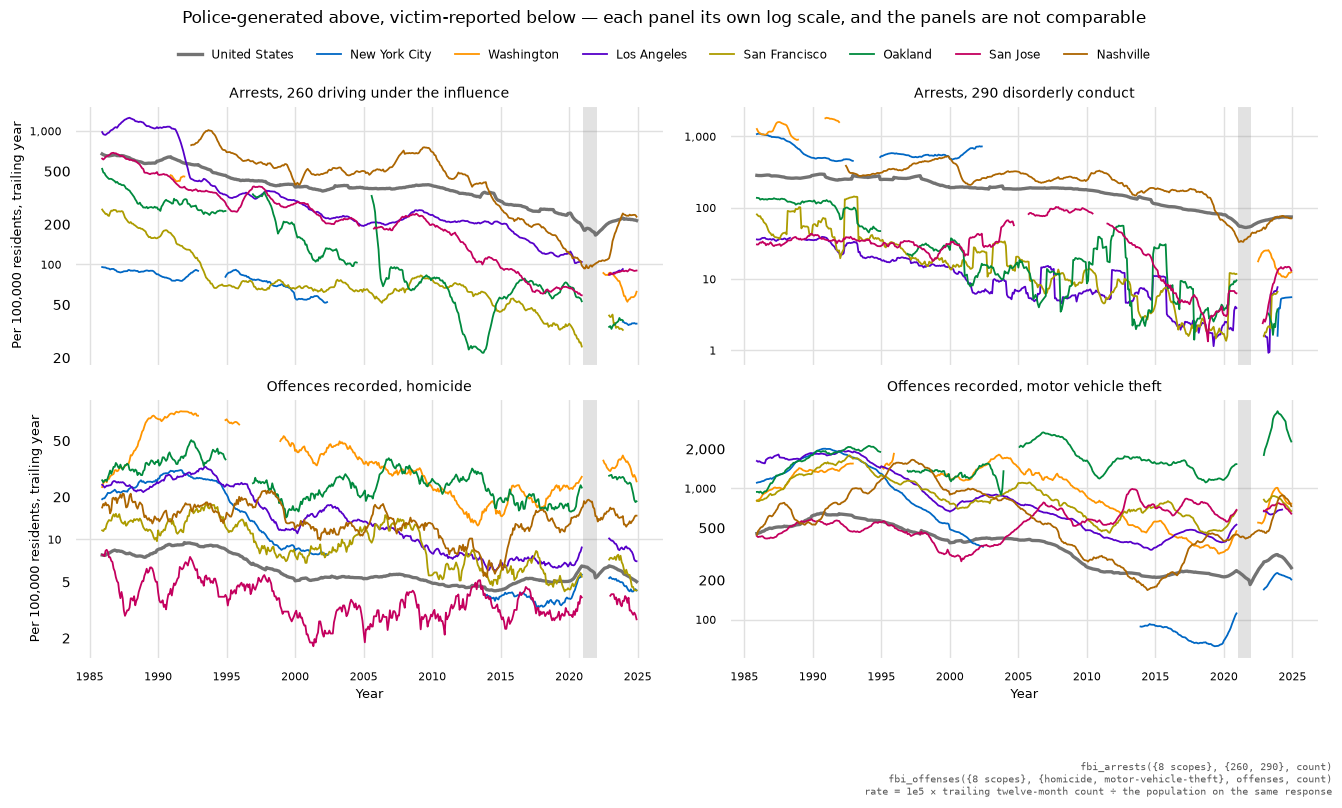

In [7]:
def ladder(axis: Any) -> None:
    """Log-scale tick labels that stay readable whatever decade the panel spans.

    Not in ``utils/filing`` and not shared: it is a drawing decision rather
    than part of the filing rule, and that module is the filing rule plus the
    one figure stamp both notebooks already share.
    A panel spanning less than a decade has one labelled tick unless the minor
    ticks carry labels too, and one spanning three decades gets an unreadable
    ladder of them, so the labels thin out as the range widens. A rate below
    one still has to read as a number: Los Angeles' disorderly-conduct line
    reaches 0.9 arrests per 100,000 residents in a trailing year.
    """
    ticks = FuncFormatter(lambda value, _: f"{value:,.0f}" if value >= 1 else f"{value:.2g}")
    axis.yaxis.set_major_formatter(ticks)
    low, high = axis.get_ylim()
    subs = (2, 3, 5) if high / low < 30 else (2, 5) if high / low < 300 else ()
    if subs:
        axis.yaxis.set_minor_locator(LogLocator(base=10, subs=subs, numticks=20))
        axis.yaxis.set_minor_formatter(ticks)
    else:
        axis.yaxis.set_minor_formatter(NullFormatter())


PANELS = [("arr", "260", "Arrests, 260 driving under the influence"),
          ("arr", "290", "Arrests, 290 disorderly conduct"),
          ("off", "homicide", "Offences recorded, homicide"),
          ("off", "motor-vehicle-theft", "Offences recorded, motor vehicle theft")]

figure, axes = pyplot.subplots(2, 2, figsize=(13.5, 8.0), sharex=True)
for (route, key, title), axis in zip(PANELS, axes.flat):
    axis.set_axisbelow(True)
    axis.axvspan(date2num(SRS_END), date2num(datetime(2022, 1, 1)),
                 color="0.55", alpha=0.25, lw=0)
    for scope in SCOPES:
        record = (arrested if route == "arr" else recorded)[key, scope]
        axis.plot(record.dates, record.rate, color=SCOPES[scope]["colour"],
                  lw=2.4 if scope == "national" else 1.3, label=SCOPES[scope]["name"],
                  zorder=2 if scope == "national" else 3)
    axis.set_yscale("log")
    ladder(axis)
    axis.set_title(title, fontsize=10)
    axis.tick_params(labelsize=8)
for axis in axes[:, 0]:
    axis.set_ylabel("Per 100,000 residents, trailing year", fontsize=9)
for axis in axes[1, :]:
    axis.set_xlabel("Year", fontsize=9)
handles = axes[0, 0].get_lines()[:len(SCOPES)]
figure.suptitle("Police-generated above, victim-reported below — each panel its own log "
                "scale, and the panels are not comparable", fontsize=12, y=0.99)
figure.legend(handles, [str(handle.get_label()) for handle in handles], loc="upper center",
              bbox_to_anchor=(0.5, 0.955), ncols=len(SCOPES), fontsize=8.5, frameon=False)
figure.tight_layout()
figure.subplots_adjust(top=0.87)
stamp_source("fbi_arrests({8 scopes}, {260, 290}, count)",
             "fbi_offenses({8 scopes}, {homicide, motor-vehicle-theft}, offenses, count)",
             "rate = 1e5 × trailing twelve-month count ÷ the population on the same response",
             figure=figure)

Four panels, each on its own log scale, and **the panels are not comparable
with each other** — disorderly-conduct arrests reach 0.9 per 100,000 and car
thefts 3,880. Within a panel the eight lines are comparable, with the usual
caution that a level crossing the grey band crosses a break.

**Peak to trough the two rows are more alike than they look**, and that is
worth saying before anything else. From each line's own high to its own low,
disorderly conduct falls 82% (the nation) to 100% (New York) and recorded car
theft falls 72% (the nation, San Jose) to 97% (New York). The difference
between the rows is **not** the amplitude, and a reader who took the visual
impression of the top row's collapse as the finding would be reading the log
scale rather than the data.

**The difference is the shape, and specifically the ending.** The top row falls
and stays down: the four Californian cities arrest for disorderly conduct at 1.7
to 4.1 per 100,000 in the year to December 2019 against 35.8 to 124.1 in 1990,
and none of them recovers before its series ends. The bottom row mostly falls
over the same span — by a factor of two to five at Los Angeles, San Francisco
and Oakland, but only 1.07 for Nashville's homicide, while San Jose's car theft
rises 10% and then **turns back up after 2020**, which is the one movement in
the figure that happens in the anchored row and not in the proactive one.

**The bottom-right panel turns up hard after 2020 and the top row does not
follow it.** Oakland's recorded car theft goes 1,161 per 100,000 in the year to
December 2019 to 3,880 in 2023 and 2,279 in 2024; Washington 326 to 766; New
York 66 to 202; Nashville 403 to 732. Those are the years in which the
proactive lines are at or near their forty-year floors. The pairing is what the
notebook is for and it is **not** a finding about cause: the same years contain
a pandemic, a change in what a stolen car is worth, a widely reported
vulnerability in two makes of car, and seven departments' own decisions.

**The grey band is mostly empty on both rows** and that is the 2021 reporting
hole, not a quiet year;
[`walkthrough.ipynb`](walkthrough.ipynb) section 2 takes the national dip apart
and section 6 below checks it against something outside the police entirely.

**Where a top-row line simply stops, read section 1's table first.** Los
Angeles', San Francisco's and Oakland's arrest series end in 2023 or 2024 while
their offence series continue; Washington's and New York's disappear for
decades. None of that is enforcement.

## 4. Instrument 2 — arrests per officer

Arrests per resident asks how much enforcement a population received. Arrests
per *officer* asks something else: how much each unit of capacity produced. The
two can move in opposite directions, and where they do, the difference is about
the department rather than the city.

`fbi_employment` is agency-grain only — the national and state endpoints answer
with nulls — so there is no national line here, and this instrument exists for
the seven cities alone. The counts are male plus female sworn officers, summed
by the response model. The denominator for a rate is the population on the
*offence* response rather than the participated population the employment
payload carries, which is sometimes zero.

Two years are printed. A **matched year** for each city — the latest calendar
year in which twelve arrest months can be read *and* a headcount was filed,
which is not the same year for all seven — and then every city on one common
year, so that the matched-year figures cannot be read as a cross-section when
they are not one.

In [8]:
def per_officer(scope: str, year: int, codes: Sequence[str] = ("all",)) -> float:
    """Calendar-year arrests under *codes* per sworn officer, NaN if either leg is out."""
    people = officers[scope].get(year)
    counts = [arrested[code, scope].calendar(year) for code in codes]
    return sum(counts) / people if people and all(numpy.isfinite(counts)) else float("nan")


def residents(scope: str, year: int) -> float:
    """The city's December population, from the homicide response."""
    record = recorded["homicide", scope]
    return record.at(record.population, f"12-{year}")


print("Matched years: the latest calendar year with twelve readable arrest months and a "
      "filed headcount")
print(f"{'place':16}{'year':>6}{'arrests':>11}{'officers':>10}{'per officer':>13}"
      f"{'officers/100k':>15}{'arrests/100k':>14}")
for scope in CITIES:
    years = [year for year in sorted(officers[scope], reverse=True)
             if numpy.isfinite(arrested["all", scope].calendar(year))]
    year = years[0]
    total, people = arrested["all", scope].calendar(year), officers[scope][year]
    print(f"{SCOPES[scope]['name']:16}{year:>6}{total:11,.0f}{people:10,.0f}"
          f"{total / people:13.1f}{1e5 * people / residents(scope, year):15.0f}"
          f"{1e5 * total / residents(scope, year):14,.0f}")

for year in (2019, 2024):
    print(f"\nEvery city on one year, {year}")
    print(f"{'place':16}{'arrests/officer':>17}{'260+290/officer':>17}"
          f"{'officers/100k':>15}")
    for scope in CITIES:
        total, proactive = per_officer(scope, year), per_officer(scope, year, CORE)
        people = officers[scope].get(year)
        print(f"{SCOPES[scope]['name']:16}"
              + (f"{total:17.1f}" if numpy.isfinite(total) else f"{'—':>17}")
              + (f"{proactive:17.2f}" if numpy.isfinite(proactive) else f"{'—':>17}")
              + (f"{1e5 * people / residents(scope, year):15.0f}"
                 if people and numpy.isfinite(residents(scope, year)) else f"{'—':>15}"))

Matched years: the latest calendar year with twelve readable arrest months and a filed headcount
place             year    arrests  officers  per officer  officers/100k  arrests/100k
New York City     2024    227,952    33,307          6.8            401         2,747
Washington        2024     21,152     3,276          6.5            467         3,012
Los Angeles       2023     49,181     8,916          5.5            235         1,299
San Francisco     2023     11,341     1,869          6.1            239         1,449
Oakland           2023      5,383       710          7.6            167         1,265
San Jose          2024     14,527     1,056         13.8            110         1,518
Nashville         2024     19,636     1,540         12.8            220         2,809

Every city on one year, 2019
place             arrests/officer  260+290/officer  officers/100k
New York City                   —                —            436
Washington                      —                —   

**On matched years the spread is a factor of two and a half, and it does not
follow staffing.** San Jose 13.8 arrests per officer in 2024 and Nashville 12.8,
against Oakland 7.6 in 2023, New York 6.8 in 2024, Washington 6.5 in 2024, San
Francisco 6.1 in 2023 and Los Angeles 5.5 in 2023 — all seven, since leaving one
out is how a spread gets quoted wider than it is. Washington fields **467
officers per 100,000 residents against San Jose's 110** — four and a quarter
times as many police per resident — and each of them is credited with fewer than
half as many arrests.

**Two of those figures are recomputed rather than carried over, and the
recomputation matters.** Reading a rough arrests-per-officer off an arrest rate
from one year and a staffing rate from another puts Oakland near 9.8; on matched
2023 data, its own arrests over its own headcount, it is **7.6**. Most of that
difference is not the year mismatch: computed on 2022 for both legs Oakland is
9.41, so mixing years costs about a fifth of the gap and the rest is 2023, the
year the matched table can use, in which its arrests fell to 5,383 — and it is
the reason this table insists on one year for both legs.

**The common-year tables say the matched-year one is not a cross-section.** In
2019 neither New York nor Washington has a readable arrest year at all, and the
five that do run 6.8 (Los Angeles) to 17.2 (San Jose); in 2024 Los Angeles, San
Francisco and Oakland have none. **No single year holds all seven**, which is a
fact about the filing schedule and not about the departments, and it means the
seven-city comparison above is assembled from 2023 and 2024 and should be read
with that in it.

**The proactive part is a fortieth to a tenth of the whole.** Arrests under
codes 260 and 290 per officer in 2019: San Francisco 0.14, Oakland 0.44, Los
Angeles 0.49, San Jose 0.64, Nashville 0.93. In 2024 New York 0.10, Washington
0.16, San Jose 0.94, Nashville 1.36. An officer in San Francisco made one
arrest for drunk driving or disorderly conduct every seven years of the
notional average; in Nashville, one or more a year. That is a real difference
between two departments' use of their people — and it is also two states' liquor
law, two cities' street life and two forces' allocation of officers to traffic
duty, none of which these series carry.

**What arrests per officer cannot be read as.** Not productivity: an arrest is
an occasion, not an outcome, and the walkthrough's section 3 is the definition.
Not effort: a department that spends its hours on investigations rather than
stops makes fewer arrests per officer by doing more work. And not capacity
either — a headcount is sworn officers, not officers on the street, and nothing
in `fbi_employment` distinguishes patrol from administration.

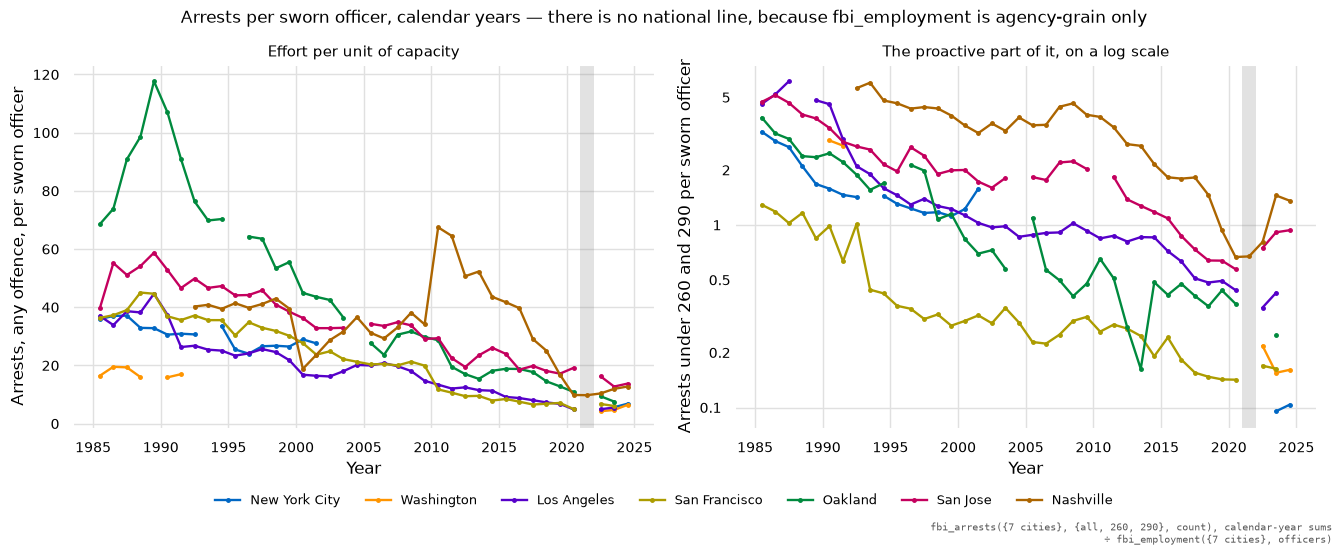

In [9]:
figure, (left, right) = pyplot.subplots(1, 2, figsize=(13.5, 5.5), sharex=True)
for axis in (left, right):
    axis.set_axisbelow(True)
    axis.axvspan(date2num(SRS_END), date2num(datetime(2022, 1, 1)),
                 color="0.55", alpha=0.25, lw=0)
    axis.set_xlabel("Year")
# Every year on the axis, with NaN where the pair cannot be read, so that a
# gap breaks the line. Plotting only the readable years instead joins 1991 to
# 2022 with a straight segment across Washington's thirty-one-year hole, which
# reads as a trend and is nothing of the kind.
SPAN = range(1985, 2025)
for scope in CITIES:
    for axis, codes in ((left, ("all",)), (right, CORE)):
        # An annual headcount sits at mid-year rather than on the January boundary.
        axis.plot([datetime(year, 7, 1) for year in SPAN],
                  [per_officer(scope, year, codes) for year in SPAN],
                  color=SCOPES[scope]["colour"], lw=1.7, marker="o", markersize=2.5,
                  label=SCOPES[scope]["name"])
left.set_ylabel("Arrests, any offence, per sworn officer")
left.set_title("Effort per unit of capacity", fontsize=11)
right.set_ylabel("Arrests under 260 and 290 per sworn officer")
right.set_title("The proactive part of it, on a log scale", fontsize=11)
right.set_yscale("log")
ladder(right)
figure.suptitle("Arrests per sworn officer, calendar years — there is no national line, "
                "because fbi_employment is agency-grain only", fontsize=12)
handles = left.get_lines()[:len(CITIES)]
figure.legend(handles, [str(handle.get_label()) for handle in handles], loc="lower center",
              bbox_to_anchor=(0.5, 0.055), ncols=len(CITIES), fontsize=9, frameon=False)
figure.tight_layout()
stamp_source("fbi_arrests({7 cities}, {all, 260, 290}, count), calendar-year sums",
             "÷ fbi_employment({7 cities}, officers)", figure=figure)
figure.subplots_adjust(bottom=0.22, top=0.88)

**The left panel falls for thirty years and flattens; the right one falls
further and keeps falling.** The two panels share a denominator and differ only
in which arrests the numerator counts, so the gap between them is the change in
the *mix* — and the mix moved against the proactive codes in every city that
can be followed across the period.

**The right panel is on a log scale because it has to be.** San Francisco runs
1.18 proactive arrests per officer in 1986 and 0.14 in 2019, a seventh of one;
drawn linearly against Nashville's the line would be indistinguishable from the
axis. Equal vertical distances are equal proportional changes, which is the
comparison worth making when the levels are two orders of magnitude apart.

**Nashville and San Jose turn up at the end of the right panel** — 0.93 to 1.36
and 0.64 to 0.94 between 2019 and 2024 — and they are the two cities whose
arrest series cross those years without a hole. Los Angeles, San Francisco and
Oakland have no 2024 point at all, so the apparent convergence at the right-hand
edge is partly the cities that are missing from it.

**The gaps are drawn as gaps, which is why Washington and New York are two
segments each.** Washington has a readable arrest year and a filed headcount in
1985–1988, 1990, 1991 and then not again until 2022; New York's run ends in
2001 and resumes in 2023. Joining those segments with a line would put a
thirty-one-year and a twenty-one-year straight edge through the middle of the
panel, and that edge would look exactly like a trend.

**Oakland's spike is real filing and it is the largest thing in the left
panel.** The department filed twelve full months in 1989 running 5,141 to 6,566
arrests each — 71,784 for the year, 19,597 per 100,000 residents, about one
arrest for every five people who lived there. That is half as much again as the
highest 1990 figure in [`walkthrough.ipynb`](walkthrough.ipynb)'s table, and
nothing in the response says what it was.

**Both panels also end in the 2021 band.** Reading a line across it compares a
department's last pre-break year with its first year back, which
[`enforcement.ipynb`](enforcement.ipynb) section 3 shows is the least
trustworthy year a department has.

## 5. Instrument 3 — composition drift

The levels of a badly-reported offence are uninterpretable: nobody knows what
share of larcenies reach a department, and the share moves. A **ratio** of a
badly-reported offence to a well-reported one is not uninterpretable in the
same way. If both offences happened at unchanged rates and only the reporting
of the first drifted, the ratio moves by exactly the drift — the real levels
cancel and the reporting difference does not.

**Larceny per motor vehicle theft** is the pairing. Larceny is the offence with
the weakest reporting compulsion of the eight — a stolen bag below a
deductible, with no insurer to satisfy and no realistic prospect of recovery,
is the archetypal unreported crime — and motor vehicle theft is the strongest
outside homicide. **Robbery per motor vehicle theft** is printed beside it as a
second reading with a different numerator.

The trap in the method is simple and fatal if ignored: **a ratio has two ends.**
The cell below therefore prints both ends as well as the ratio, because a ratio
that halves because its denominator doubled says nothing at all about the
reporting of its numerator.

In [10]:
RATIO_YEARS = (1990, 2000, 2010, 2015, 2019, 2023, 2024)

for over, label in (("larceny", "Larceny"), ("robbery", "Robbery")):
    print(f"{label} recorded per motor vehicle theft recorded, twelve months to December")
    print(f"{'place':16}" + "".join(f"{year:>9}" for year in RATIO_YEARS))
    for scope in SCOPES:
        def ratio(year: int, scope: str = scope, over: str = over) -> float:
            return (recorded[over, scope].december(year)
                    / recorded["motor-vehicle-theft", scope].december(year))
        print(f"{SCOPES[scope]['name']:16}" + cells(ratio, RATIO_YEARS, "9.2f"))
    print()

print("Which end moved, 2019 to the latest December both legs can be read")
print(f"{'place':16}{'larceny per 100k':>25}{'vehicle theft per 100k':>27}"
      f"{'the ratio':>19}{'denominator':>13}")
for scope in SCOPES:
    # The latest year BOTH legs are readable, not just the numerator: Los
    # Angeles files a readable larceny 2024 and no readable car theft, and
    # taking the numerator's year alone prints a ratio against a NaN.
    last = next(year for year in (2024, 2023)
                if numpy.isfinite(recorded["larceny", scope].december(year))
                and numpy.isfinite(recorded["motor-vehicle-theft", scope].december(year)))
    larceny = (recorded["larceny", scope].december(2019),
               recorded["larceny", scope].december(last))
    theft = (recorded["motor-vehicle-theft", scope].december(2019),
             recorded["motor-vehicle-theft", scope].december(last))
    # In logs the two ends add: log(ratio) = log(larceny) - log(theft), so the
    # share of the move each end carries is a number rather than an impression.
    moved = (numpy.log(larceny[1] / larceny[0]), numpy.log(theft[1] / theft[0]))
    print(f"{SCOPES[scope]['name']:16}"
          f"{larceny[0]:8,.0f} → {larceny[1]:<7,.0f}{100 * (larceny[1] / larceny[0] - 1):+5.0f}%"
          f"{theft[0]:12,.0f} → {theft[1]:<7,.0f}{100 * (theft[1] / theft[0] - 1):+5.0f}%"
          f"{larceny[0] / theft[0]:10.2f} → {larceny[1] / theft[1]:<5.2f}"
          f"{abs(moved[1]) / (abs(moved[0]) + abs(moved[1])):12.0%}"
          + (f"  (to {last})" if last != 2024 else ""))
print("\n'denominator' is |Δlog car theft| ÷ (|Δlog larceny| + |Δlog car theft|): the "
      "share of the\nmove in the ratio that the well-reported offence is carrying")

Larceny recorded per motor vehicle theft recorded, twelve months to December
place                1990     2000     2010     2015     2019     2023     2024
United States        4.81     5.80     8.30     7.94     7.00     4.17     4.92
New York City        1.83     3.90        —    14.67    19.36     8.99    10.11
Washington           3.74     3.28     3.71     7.57    11.24     2.88     3.42
Los Angeles          1.93     2.57     3.24     3.79     4.24     2.61        —
San Francisco        3.13     4.39     6.12     5.92     9.39     4.83     3.89
Oakland              2.66     2.40     1.66     2.32     4.01     1.37     1.83
San Jose             5.57     4.82     2.35     1.88     2.44     1.82     2.42
Nashville            5.80     5.03    11.29    12.70     7.87     4.13     4.60

Robbery recorded per motor vehicle theft recorded, twelve months to December
place                1990     2000     2010     2015     2019     2023     2024
United States        0.39     0.36     0.50  

**The ratio falls in all eight scopes between 2019 and the last readable
December, and in most of them the denominator is what moved.** Nationally
larceny per car theft goes 7.00 to 4.92; Washington 11.24 to 3.42; San
Francisco 9.39 to 3.89; New York 19.36 to 10.11; Oakland 4.01 to 1.83;
Nashville 7.87 to 4.60; Los Angeles 4.24 to 2.61 to 2023; San Jose 2.44 to
2.42. **New York's larceny rose 60% over those years and its ratio still
halved**, because its recorded car theft rose 207%.

So read plainly: this is mostly a **motor-vehicle-theft event**, not a larceny
reporting event. Recorded car theft rose in all eight, by +9% (San Jose) to
+207% (New York), while larceny moved anywhere from −42% to +60%. The last
column puts a number on it: the denominator carries **91% of the log move at
Nashville, 89% at Los Angeles, 86% at Oakland, 72% at Washington and 70% at
New York** — the majority of the move in six of the eight. Composition drift
did exactly what the method promises, producing a large uniform eight-scope
signal, and the signal is mostly in the wrong term. A ratio built to cancel the
real levels cancels nothing when one of the real levels doubles.

**San Francisco is the exception, and it is the city the question was asked
about.** There the denominator carries only 38% of the move: larceny fell 42%
against a car theft that rose 40%, so most of that ratio's collapse really is
the numerator. That is the one place in this table where composition drift is
measuring what it was built to measure — and what it measures is that San
Francisco's recorded crime became much less larceny relative to car theft
between 2019 and 2024. Whether that is fewer thefts, fewer reported thefts or
fewer recorded reports, the ratio cannot say; it says only that the movement is
not in the anchored leg.

**Robbery per motor vehicle theft confirms the diagnosis.** It falls in all
eight too — nationally 0.37 to 0.24, New York 2.43
to 0.99, Nashville 0.72 to 0.22 — and robbery has a reporting compulsion much
closer to car theft's than larceny's has. Two numerators of very different
reportability falling by similar proportions against one denominator is what a
denominator moving looks like.

**Where the method does work here is the earlier stretch.** San Francisco's
larceny per car theft runs 3.13 in 1990, 4.39 in 2000, 6.12 in 2010, 9.39 in
2019 — a tripling over three decades while its car theft fell by two thirds and
its homicide by two thirds, so this one is mostly the numerator. New York's
goes 1.83 to 19.36 over the same window. Whether that is more larceny, more
larceny reported, or a change in what a department records as one, the ratio
cannot say either — it only says the composition moved, and it says it without
needing the levels to mean anything.

**The honest summary of instrument 3**: it is the cheapest of the four, it
needs no outside data, and it is worthless without the decomposition printed
beside it.

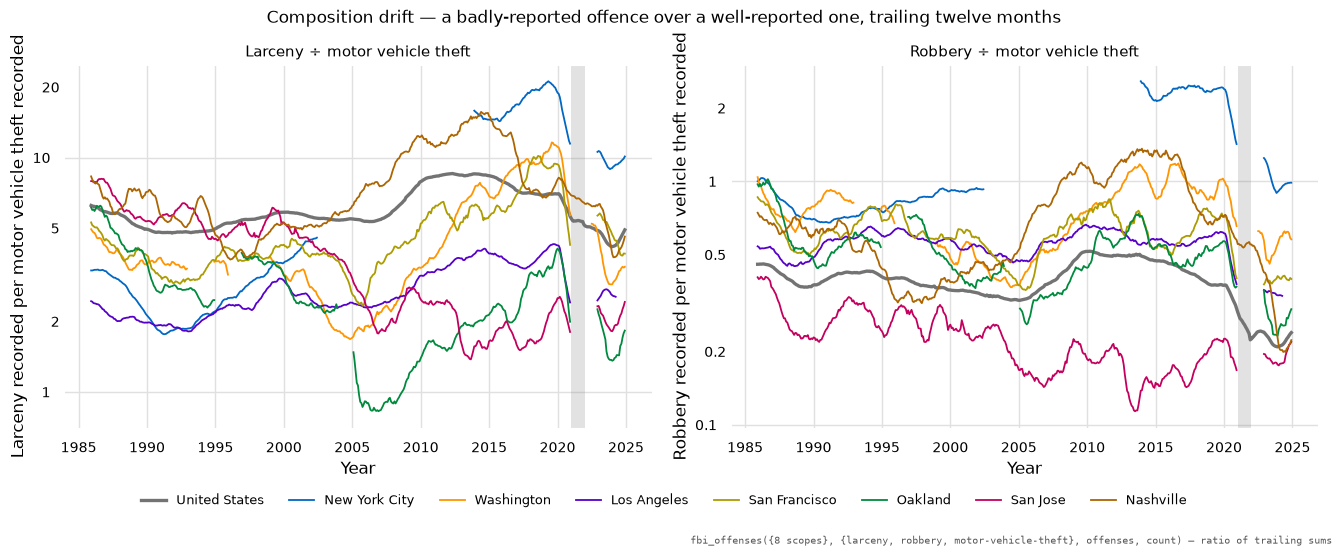

In [11]:
figure, axes = pyplot.subplots(1, 2, figsize=(13.5, 5.5), sharex=True)
for axis, (over, label) in zip(axes, (("larceny", "Larceny"), ("robbery", "Robbery"))):
    axis.set_axisbelow(True)
    axis.axvspan(date2num(SRS_END), date2num(datetime(2022, 1, 1)),
                 color="0.55", alpha=0.25, lw=0)
    for scope in SCOPES:
        # Both legs are trailing sums of readable months, so a window with a
        # gap in either offence is NaN in the ratio and simply not drawn.
        ratio = (recorded[over, scope].trailing
                 / recorded["motor-vehicle-theft", scope].trailing)
        axis.plot(recorded[over, scope].dates, ratio, color=SCOPES[scope]["colour"],
                  lw=2.4 if scope == "national" else 1.3, label=SCOPES[scope]["name"],
                  zorder=2 if scope == "national" else 3)
    axis.set_yscale("log")
    ladder(axis)
    axis.set_xlabel("Year")
    axis.set_ylabel(f"{label} recorded per motor vehicle theft recorded")
    axis.set_title(f"{label} ÷ motor vehicle theft", fontsize=11)
handles = axes[0].get_lines()[:len(SCOPES)]
figure.suptitle("Composition drift — a badly-reported offence over a well-reported one, "
                "trailing twelve months", fontsize=12)
figure.legend(handles, [str(handle.get_label()) for handle in handles], loc="lower center",
              bbox_to_anchor=(0.5, 0.055), ncols=len(SCOPES), fontsize=9, frameon=False)
figure.tight_layout()
stamp_source("fbi_offenses({8 scopes}, {larceny, robbery, motor-vehicle-theft}, "
             "offenses, count) — ratio of trailing sums", figure=figure)
figure.subplots_adjust(bottom=0.22, top=0.88)

**Both panels turn down sharply at the right-hand edge and they turn down
together**, which is the decomposition again: one denominator, two numerators,
one shared collapse. If the right-hand fall were larceny reporting drifting
away, the robbery panel would not share it.

**The long climb in the left panel is the part worth keeping.** New York's
larceny per car theft rises more than tenfold between 1990 and 2019, 1.83 to
19.36; San Francisco and Washington roughly double or triple; and Nashville's
1.36 is below the national 1.46 it is being contrasted with. Read as composition
it says those four departments' recorded crime became much more larceny and much
less car theft over thirty years; read as reporting it says larceny reporting
rose relative to car-theft reporting; read as enforcement it says nothing at
all, and the notebook is not in a position to choose.

**The lines are drawn only where both legs are readable in the same
twelve-month window**, which is why New York's is absent for its quarterly
decade and everyone's is absent through the grey band.

## 6. Instrument 4 — the external check

Every instrument so far is built out of police records, so every one of them
can move because the police changed. The fourth is not. A death certificate is
completed by a physician, coroner or medical examiner, registered by a state
vital-statistics office and coded to ICD-10 by NCHS. **No police decision
touches it.** If recorded homicide falls relative to certified assault deaths,
something changed in the recording and not in the dying.

This is the strongest instrument in the notebook and the narrowest: it works
for one offence. Nothing certifies a burglary.

**The death side costs no request.** `notebooks/cdc/` already holds a WONDER
pull of the assault codes — X85–Y09 plus Y87.1, the NVSR definition of
homicide, minus the two terrorism codes WONDER's finder will not take with
their asterisks — from database D76 for 1999–2020 and D158 for 2018–2024. The
cell below reads those two files off disk, checks they agree in the three
overlapping years and splices them, exactly as `utils/wonder_series.stitch`
does for the CDC notebooks. The FBI side is the national homicide series this
notebook already fetched, summed to calendar years.

In [12]:
#: The cached WONDER pulls the CDC notebooks made. Read rather than requested:
#: WONDER self-throttles at about one query every two minutes and refuses
#: plain HTTP clients outright, so a live query here would be both slow and
#: fragile, and the pull is already on disk and already checked.
WONDER = _FBI.parents[0] / "cdc" / "data" / "wonder"
by_database = {name: {row["year"]: row for row in
                      json.loads((WONDER / f"homicide_{name}.json").read_text())}
               for name in ("D76", "D158")}
overlap = sorted(set(by_database["D76"]) & set(by_database["D158"]))
agree = all(by_database["D76"][year]["deaths"] == by_database["D158"][year]["deaths"]
            for year in overlap)
# D76 through its last year, D158 after: the splice rule utils/wonder_series
# uses, kept because the two agree exactly in the overlap.
splice = max(by_database["D76"])
deaths = ({year: row for year, row in by_database["D76"].items() if year <= splice}
          | {year: row for year, row in by_database["D158"].items() if year > splice})

print(f"WONDER, assault X85–Y09 and Y87.1, underlying cause of death, whole United States")
print(f"  D76 {min(by_database['D76'])}–{max(by_database['D76'])}, "
      f"D158 {min(by_database['D158'])}–{max(by_database['D158'])}, spliced at {splice}")
print(f"  they overlap in {overlap} and agree in every one of them: {agree}")
print(f"  read from {WONDER} — no request spent here")

nation = recorded["homicide", "national"]
print(f"\n{'year':6}{'FBI recorded':>14}{'coverage':>10}{'death records':>15}"
      f"{'FBI ÷ records':>15}{'÷ coverage':>13}")
paired: list[tuple[int, float, float, float]] = []
for year in sorted(deaths):
    filed = nation.calendar(year)
    if not numpy.isfinite(filed):
        continue
    covered = float(numpy.nanmean([nation.coverage[i] for i, date in enumerate(nation.dates)
                                   if date.year == year])) / 100
    certified = float(deaths[year]["deaths"])
    paired.append((year, filed, certified, covered))
    print(f"{year:<6}{filed:14,.0f}{100 * covered:9.1f}%{certified:15,.0f}"
          f"{filed / certified:15.3f}{filed / covered / certified:13.3f}")

raw = numpy.array([filed / certified for _, filed, certified, _ in paired])
adjusted = numpy.array([filed / covered / certified
                        for _, filed, certified, covered in paired])
years = [year for year, *_ in paired]
print(f"\nas recorded: {raw.min():.3f} to {raw.max():.3f}, "
      f"lowest in {years[int(raw.argmin())]}")
print(f"over coverage: {adjusted.min():.3f} to {adjusted.max():.3f}, "
      f"lowest in {years[int(adjusted.argmin())]}; "
      f"{adjusted[years.index(2021)]:.3f} in 2021")
print(f"the trend in the adjusted ratio: {adjusted[0]:.3f} in {years[0]} against "
      f"{adjusted[-1]:.3f} in {years[-1]}")

WONDER, assault X85–Y09 and Y87.1, underlying cause of death, whole United States
  D76 1999–2020, D158 2018–2024, spliced at 2020
  they overlap in [2018, 2019, 2020] and agree in every one of them: True
  read from /Users/troy/Develop/gly.fish/meida/notebooks/cdc/data/wonder — no request spent here

year    FBI recorded  coverage  death records  FBI ÷ records   ÷ coverage
1999          14,360     89.4%         16,889          0.850        0.951
2000          14,728     89.8%         16,765          0.878        0.978
2001          15,316     90.6%         17,386          0.881        0.972
2002          15,617     92.2%         17,637          0.885        0.960
2003          15,814     91.8%         17,732          0.892        0.971
2004          15,607     93.5%         17,357          0.899        0.961
2005          16,179     93.2%         18,124          0.893        0.958
2006          16,931     95.7%         18,573          0.912        0.952
2007          16,878     96.3% 

**The ratio is stable for a quarter of a century and then 2021 happens.**
Recorded homicide over certified assault deaths runs between 0.850 and 0.919 in
every year from 1999 to 2024 except one. In **2021 it is 0.689** — the FBI
recorded 17,933 homicides against 26,031 death certificates, a gap of eight
thousand deaths that a police programme did not write down.

**Dividing by the FBI's own reporting coverage puts it back.** 2021's coverage
is 77.0%, against 89.4% to 98.1% across the other years of the table and 94.8%
to 96.4% in the five years either side of it, and 17,933 ÷ 0.770 ÷ 26,031 =
**0.895** — inside the range of every other year in the table. The walkthrough
makes this argument from the coverage field alone, which is a number the
programme supplies about itself; here the same correction is checked against a
count no part of the programme produced, and it holds to three decimal places of
the neighbouring years. **2021 was a badly observed year and not a quiet one**,
confirmed from outside.

That is the instrument working exactly as designed: a measurement failure
detected, dated and sized by an anchor the failure could not reach.

**The residual 10–12% is not error, and not withdrawal either.** The FBI's
murder and nonnegligent manslaughter excludes justifiable homicides and
negligent manslaughter; a death certificate codes a justifiable killing by a
civilian as assault all the same (only killings by legal intervention go to
Y35, outside X85–Y09). The certificate is filed by year of death and the
offence by month of report. A gap of this size in this direction is what those
definitions predict, and it is the reason the **level** of the ratio carries no
information and only its **movement** does.

**And there is a slow movement, which is the part to be careful about.** The
coverage-adjusted ratio runs 0.951 in 1999 and 0.888 in 2024 — about six points
over twenty-five years, drifting rather than stepping. Recorded homicide has
been falling relative to death certificates, slowly, for a generation. At least
four things would produce that and this pair cannot choose between them: a
rising share of killings classified as justifiable and so dropped from the
offence count; classification drift on certificates; the coverage figure itself
being a poorer correction than it looks, since it is a population share and not
a homicide share; and a genuine drift in what departments record. It is the
right size to be any of them.

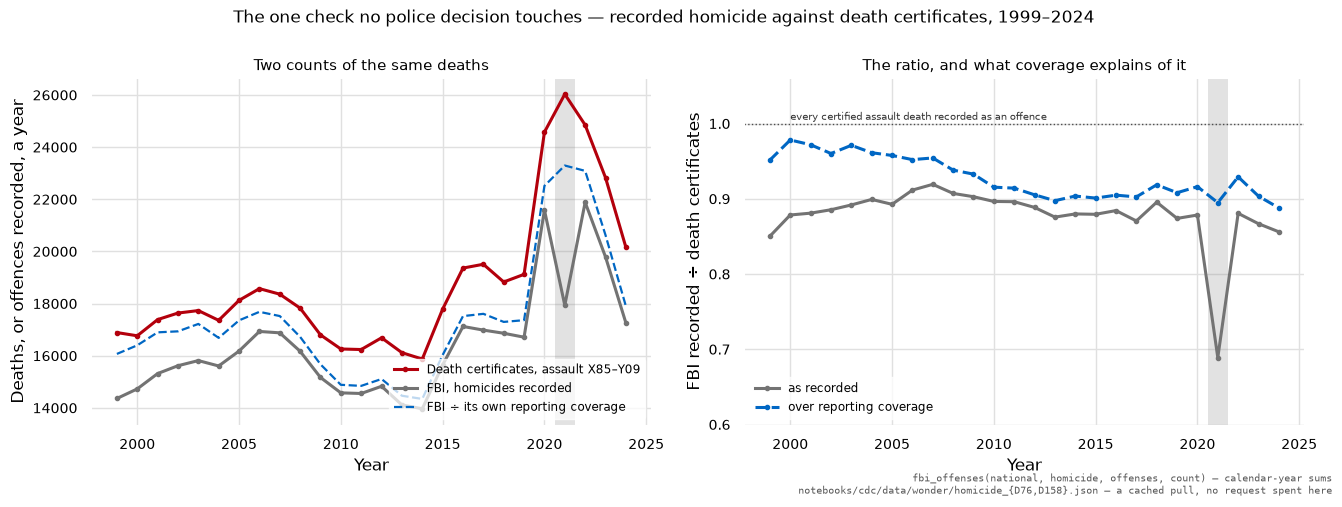

In [13]:
figure, (left, right) = pyplot.subplots(1, 2, figsize=(13.5, 5.0), sharex=True)
for axis in (left, right):
    axis.set_axisbelow(True)
    axis.axvspan(2020.5, 2021.5, color="0.55", alpha=0.25, lw=0)
    axis.set_xlabel("Year")
certified = [certified for _, _, certified, _ in paired]
filed = [filed for _, filed, _, _ in paired]
left.plot(years, certified, color="#B3000C", lw=2.2, marker="o", markersize=3,
          label="Death certificates, assault X85–Y09")
left.plot(years, filed, color="0.45", lw=2.2, marker="o", markersize=3,
          label="FBI, homicides recorded")
left.plot(years, numpy.array(filed) / numpy.array([c for *_, c in paired]),
          color="#0067C4", lw=1.6, ls="--", label="FBI ÷ its own reporting coverage")
left.set_ylabel("Deaths, or offences recorded, a year")
left.set_title("Two counts of the same deaths", fontsize=11)
left.legend(fontsize=8.5, loc="lower right")
right.plot(years, raw, color="0.45", lw=2.2, marker="o", markersize=3, label="as recorded")
right.plot(years, adjusted, color="#0067C4", lw=2.2, ls="--", marker="o", markersize=3,
           label="over reporting coverage")
right.axhline(1.0, color="0.3", lw=1, ls=":")
right.text(2000, 1.005, "every certified assault death recorded as an offence", fontsize=7.5,
           alpha=0.8)
right.set_ylim(0.6, 1.06)
right.set_ylabel("FBI recorded ÷ death certificates")
right.set_title("The ratio, and what coverage explains of it", fontsize=11)
right.legend(fontsize=8.5, loc="lower left")
figure.suptitle("The one check no police decision touches — recorded homicide against "
                "death certificates, 1999–2024", fontsize=12)
figure.tight_layout()
stamp_source("fbi_offenses(national, homicide, offenses, count) — calendar-year sums",
             "notebooks/cdc/data/wonder/homicide_{D76,D158}.json — a cached pull, "
             "no request spent here", figure=figure)

The left panel is the pair of counts and the right one is their ratio, and the
right panel is the one that matters: a flat band with a single deep notch in
2021 that the dashed coverage-adjusted line does not have.

**This is national, and the cities are where the question lives.** The whole of
section 6 so far is one number a year for the whole country. A withdrawal
index built for San Francisco is not tested by a national ratio, and the next
cell asks which of these seven cities could be tested at all.

The answer turns on jurisdiction. Death certificates are tabulated by **county
of residence** (or of occurrence); FBI series here are by **police agency**. The
check is only meaningful where the two cover the same people.

In [14]:
#: Which of the seven can be set against a county death count, and why. The
#: FIPS codes are the county identifiers WONDER's location finder takes. This
#: is jurisdiction, not measurement: nothing in the FBI payloads states it,
#: and the population column is printed only to show the size of what each
#: department polices.
GEOGRAPHY: list[tuple[str, str, str, str]] = [
    ("CA0380100", "06075", "one to one",
     "City and County of San Francisco — the city and the county are the same body"),
    ("DCMPD0000", "11001", "one to one",
     "the District is a single county-equivalent with a single police force"),
    ("TN0190100", "47037", "nearly one to one",
     "Metropolitan Nashville–Davidson County; a few satellite municipalities inside "
     "the county keep small departments of their own"),
    ("NY0303000", "36005 36047 36061 36081 36085", "five, summable",
     "the five boroughs are five counties and the NYPD polices all of them, so the "
     "county deaths add to the city"),
    ("CA0010900", "06001", "a fraction", "Oakland is part of Alameda County"),
    ("CA0431300", "06085", "a fraction", "San Jose is part of Santa Clara County"),
    ("CA0194200", "06037", "a fraction", "Los Angeles is part of Los Angeles County"),
]
print(f"{'place':16}{'residents 2024':>16}  {'county FIPS':29} {'fit':18} why")
for scope, fips, fit, why in GEOGRAPHY:
    population = residents(scope, 2024)
    wrapped = textwrap.wrap(why, 44)
    print(f"{SCOPES[scope]['name']:16}{population:16,.0f}  {fips:29} {fit:18} {wrapped[0]}")
    for line in wrapped[1:]:
        print(f"{'':16}{'':16}  {'':29} {'':18} {line}")

checkable = [scope for scope, _, fit, _ in GEOGRAPHY if fit != "a fraction"]
print(f"\n{len(checkable)} of the seven could be checked this way: "
      + ", ".join(SCOPES[scope]["name"] for scope in checkable))
print(f"{7 - len(checkable)} could not, at any level of effort, because a county death "
      f"count covers people\n  their department does not police and the county's other "
      f"departments do.")

print("""
The query that would settle it, and why it is not run here
----------------------------------------------------------
clients/wonder.py's own note, live-verified in August 2026, is that "via the
API these NVSS databases cannot group/limit by geography" -- race and sex are
groupable and county is not, on the request skeletons that work. So the county
figure is specified here and NOT RUN, rather than approximated from anything.

Against D158 (single-race, 2018-2024) the request would be the skeleton in
clients/wonder.py with these overrides, and against D76 the same with 76 for
158 throughout:

    accept_datause_restrictions = true
    B_1            = D158.V1-level1        # by year
    B_2            = D158.V9               # and by county  <- the untested part
    O_location     = D158.V9               # county, not census region
    F_D158.V9      = 06075                 # the county FIPS, one at a time
    I_D158.V9      = "San Francisco County, CA"
    O_ucd          = D158.V2               # underlying cause = detailed ICD-10
    F_D158.V2      = X85,X86,...,Y09,Y87.1 # wonder_codes.HOMICIDE, less *U01/*U02
    M_1, M_2, M_3  = D158.M1, D158.M2, D158.M3   # deaths, population, crude rate

Eight requests -- three consolidated cities plus New York's five boroughs --
at WONDER's advisory one query every two minutes, so about twenty minutes
serialized, and each county-year under ten deaths comes back "Suppressed"
rather than as a number. San Francisco certifies on the order of fifty assault
deaths a year, so suppression would bite on the smaller boroughs and not on
the cities.

If B_2 is refused, as the client's note predicts, the fallback is the WONDER
web interface's own export, one query per county, which is the same data by a
route no client in this repository drives.
""")

place             residents 2024  county FIPS                   fit                why
San Francisco            802,856  06075                         one to one         City and County of San Francisco — the city
                                                                                   and the county are the same body
Washington               702,250  11001                         one to one         the District is a single county-equivalent
                                                                                   with a single police force
Nashville                698,987  47037                         nearly one to one  Metropolitan Nashville–Davidson County; a
                                                                                   few satellite municipalities inside the
                                                                                   county keep small departments of their own
New York City          8,299,271  36005 36047 36061 36081 36

**So the external check ran nationally and is specified-not-run per city.**
Three of the seven — San Francisco, Washington and Nashville — are single
departments policing single counties, and New York is five counties that sum
exactly to the city, so four of the seven could be checked against death
certificates by a route this repository does not currently drive. **Oakland,
San Jose and Los Angeles cannot be checked this way at all**, at any level of
effort: Alameda, Santa Clara and Los Angeles counties contain dozens of other
municipalities with their own police departments, so a county death count and a
city offence count have different denominators and no arithmetic reconciles
them.

That asymmetry is worth stating for its own sake. **The instrument that cannot
be fooled by a police decision is also the instrument that cannot be pointed at
most cities.** The three Californian cities this notebook watches most closely
are exactly the three it cannot anchor.

## 7. The trap — a statute moving, not a decision

A proactive arrest count falls when a department stops enforcing. It also falls
when the conduct stops being an offence, and the series look identical. Two
changes inside this window hit these cities directly.

**Proposition 64**, passed 8 November 2016, legalised possession of up to 28.5
grams of cannabis by adults in California; licensed retail sales began 1 January
2018. After that date arrest code 158 cannot measure enforcement in Los
Angeles, San Francisco, Oakland or San Jose, because the conduct it counts is
mostly no longer arrestable.

**Proposition 47**, passed 4 November 2014, reclassified theft under $950 from
a possible felony to a misdemeanour in California. That is a change in
*penalty*, not in whether the conduct is an offence, so it should not move a
recorded-offence count at all — but it is the change most often invoked to
explain San Francisco's larceny series, so the series is printed against it.

**And the courts moved vagrancy.** *Martin v. City of Boise* (Ninth Circuit,
2018) held that a city cannot punish sleeping in public where no shelter is
available, which constrained enforcement of exactly the ordinances code 300
counts across all four Californian cities here; *City of Grants Pass v.
Johnson* (2024) went the other way. Code 300 is therefore under the same trap
as code 158 in the same cities, from a different branch of government — which
is the reason the withdrawal index in section 3 is built on 260 and 290 and
reads 300 only as corroboration.

The rule that follows: **either exclude an offence whose statute moved, or use
the change as a natural experiment — but never read a statutory fall as a
discretionary one.**

In [15]:
TRAP_YEARS = (2010, 2013, 2015, 2016, 2017, 2019, 2022, 2024)
print("Cannabis possession arrests per 100,000 residents, twelve months to December")
print(f"{'place':16}" + "".join(f"{year:>9}" for year in TRAP_YEARS)
      + "   Prop 64 passes 11-2016, retail sales 01-2018")
for scope in ("national", *CALIFORNIA, "TN0190100"):
    print(f"{SCOPES[scope]['name']:16}"
          + cells(arrested["158", scope].december, TRAP_YEARS, "9.1f"))

print("\nThe fall measured either side of the statute, where both Decembers are readable")
print(f"{'place':16}{'2010':>9}{'2016':>9}{'2010 → 2016':>14}{'2016 → the last':>17}")
for scope in CALIFORNIA:
    record = arrested["158", scope]
    last = next((year for year in (2024, 2023, 2022, 2021, 2019)
                 if numpy.isfinite(record.december(year))), 0)
    before, statute, after = record.december(2010), record.december(2016), record.december(last)
    print(f"{SCOPES[scope]['name']:16}{before:9.1f}{statute:9.1f}"
          f"{100 * (statute / before - 1):13.0f}%"
          f"{100 * (after / statute - 1):11.0f}% (to {last})")

print("\nVagrancy arrests per 100,000, the same years — Martin v. Boise is 2018")
print(f"{'place':16}" + "".join(f"{year:>9}" for year in TRAP_YEARS))
for scope in ("national", *CALIFORNIA):
    print(f"{SCOPES[scope]['name']:16}"
          + cells(arrested["300", scope].december, TRAP_YEARS, "9.1f"))

print("\nSan Francisco larceny recorded per 100,000 residents, twelve months to December")
print("  Proposition 47 passes 04-11-2014")
record = recorded["larceny", "CA0380100"]
for year in (2008, 2012, 2013, 2014, 2015, 2017, 2019, 2020, 2022, 2023, 2024):
    marker = "  ← the first full year after Prop 47" if year == 2015 else ""
    print(f"    {year}  {record.december(year):8,.0f}{marker}")
after = numpy.array([value if date > datetime(2014, 11, 4) else numpy.nan
                     for date, value in zip(record.dates, record.rate)])
peak = int(numpy.nanargmax(after))
print(f"  2014 → 2015: {100 * (record.december(2015) / record.december(2014) - 1):+.0f}%; "
      f"the highest window after the vote is {after[peak]:,.0f} in "
      f"{record.dates[peak]:%Y-%m}, "
      f"{(record.dates[peak].year - 2014) * 12 + record.dates[peak].month - 11} months later")
print(f"  the highest window of the whole forty years is "
      f"{numpy.nanmax(record.rate):,.0f} in "
      f"{record.dates[int(numpy.nanargmax(record.rate))]:%Y-%m}")
print(f"  and the population it is divided by: "
      + ", ".join(f"{year} {record.at(record.population, f'12-{year}'):,.0f}"
                  for year in (2015, 2019, 2022, 2024)))

Cannabis possession arrests per 100,000 residents, twelve months to December
place                2010     2013     2015     2016     2017     2019     2022     2024   Prop 64 passes 11-2016, retail sales 01-2018
United States       191.5    192.9    138.6    146.6    158.6    123.7     65.4     55.4
Los Angeles         110.2     13.1      4.4      3.6      3.7      5.6      4.3        —
San Francisco        29.2      2.4      1.9      0.9      0.3        —      0.9        —
Oakland              26.4      3.7      5.5      7.3      8.2      2.8      3.0        —
San Jose            136.2     23.3      8.6      6.0      6.4      1.9      3.4      3.8
Nashville           568.1    926.7    504.8    510.5    469.8    154.9     33.4     34.2

The fall measured either side of the statute, where both Decembers are readable
place                2010     2016   2010 → 2016  2016 → the last
Los Angeles         110.2      3.6          -97%         12% (to 2023)
San Francisco        29.2      0.9 

**The cannabis fall is almost entirely finished before the statute changes.**
Los Angeles arrests 110.2 per 100,000 for possession in the year to December
2010 and **3.6 in the twelve months to December 2016, the year Proposition 64
passed** — down 97% before the law moved at all. San Francisco 29.2 to 0.9, −97%. San Jose 136.2 to 6.0, −96%.
Oakland 26.4 to 7.3, −72%. What remains for the statute to remove is between 3%
and 28% of the 2010 level, and what happens to it afterwards is noise at that
size: San Francisco's 0.9 per 100,000 becomes 2.4 by 2023 and Los Angeles' 3.6
becomes 4.0, both of them *rises*, on counts of a few dozen arrests a year in
cities of hundreds of thousands.

That is the trap in its most instructive form. Anybody reading code 158 across
2016 in a California city and attributing the collapse to Proposition 64 would
be attributing an effect to a cause that arrived after it. And anybody reading
it as enforcement withdrawal would be right about the timing and would still be
reading a series that stops meaning anything from 2018. **The code has to
be excluded from the withdrawal index either way**, and the exclusion has to be
made on the dates rather than on the size of the fall.

**The national line makes the same point from the other side.** Nationally
cannabis-possession arrests run 191.5 per 100,000 in 2010 and 146.6 in 2016 —
down 23% where the four California cities were down 72% to 97%, in a country
where most people's cannabis law had not yet changed. Nashville, the control
with no change of law at all, runs 568.1 in 2010 and 510.5 in 2016 and then
154.9 in 2019 and 34.2 in 2024.

**Vagrancy does not show a 2018 break at all, which is its own warning.** Los
Angeles runs 12.4 per 100,000 in 2017 and 2.2 in 2019, San Francisco 5.7 and
12.0 — one down sharply, one up by more than double, across the same circuit
decision in the same circuit in the same two years. The counts are small enough
that neither movement is worth much, and the point is not that *Martin*
did nothing: it is that a legal change to a small code is not identifiable in
these series, so the code cannot be used to measure either the law or the
enforcement.

**Proposition 47 has no level shift at it, and the timing is decisive.** San
Francisco's recorded larceny runs 3,967 per 100,000 in the year to December
2014, **4,737 in 2015 — the first full year after the proposition, up 19%** —
and its highest window after the vote, 5,059 per 100,000, comes thirty-seven
months later in December 2017. A reclassification that took effect in
November 2014 does not raise larceny
through 2017 and then collapse it in 2024. The collapse is 4,135 in 2023 to
2,619 in 2024, ten years after the vote. Whatever moved in 2024, the 2014
statute is not a candidate on the dates alone. And San Francisco **never
converted to NIBRS**, so none of this series is a counting-rule artefact
either.

**One thing the denominator cannot be blamed for.** Theft opportunity scales
with the people and vehicles present, not with the people resident, and San
Francisco's daytime population changed after 2020 in a way no series here
carries. The resident population the FBI attaches to these responses runs
886,007 in 2019, 764,693 in 2022 and 802,856 in 2024 — it *fell* 9%, which
pushes a per-resident rate **up**, while larceny per 100,000 fell 42% from 2019
to 2024. So the denominator is working against the fall rather than producing
it. That does not rescue the rate: a presence-weighted denominator would be a
different and probably better number, and the nearest one obtainable without a
new dependency is county employment by place of work, which BLS publishes
quarterly under QCEW and which `bls_series_data` on this same server would
serve. It is named here and not fetched, and every per-resident property rate
in this notebook should be read as resting on a denominator that is known to be
the wrong one.

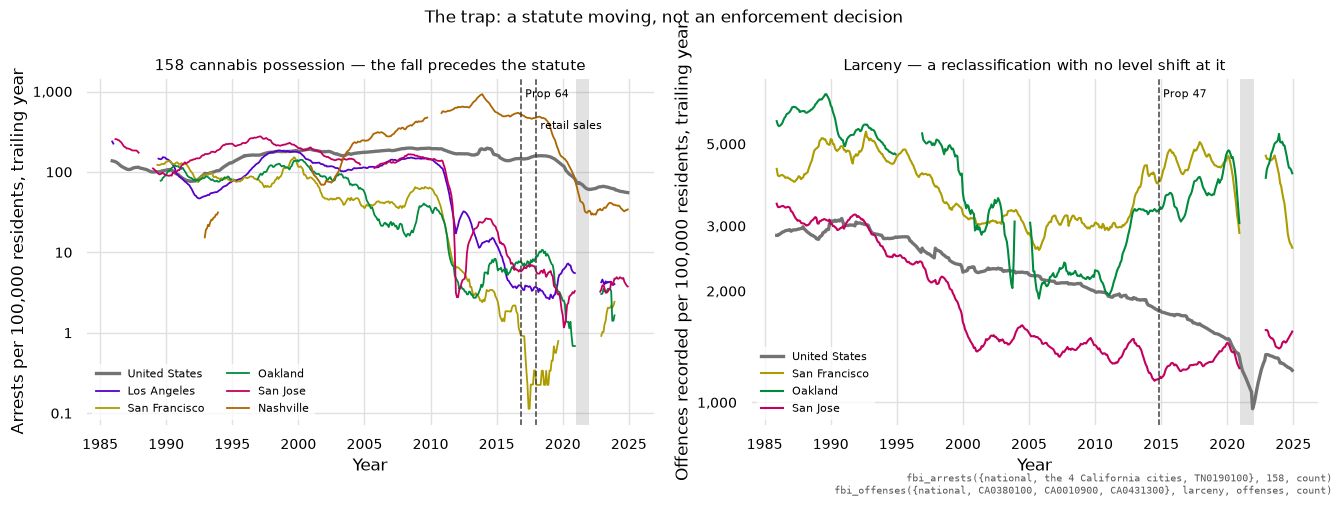

In [16]:
figure, (left, right) = pyplot.subplots(1, 2, figsize=(13.5, 5.0))
for axis in (left, right):
    axis.set_axisbelow(True)
    axis.axvspan(date2num(SRS_END), date2num(datetime(2022, 1, 1)),
                 color="0.55", alpha=0.25, lw=0)
    axis.set_xlabel("Year")
for scope in ("national", *CALIFORNIA, "TN0190100"):
    record = arrested["158", scope]
    left.plot(record.dates, record.rate, color=SCOPES[scope]["colour"],
              lw=2.4 if scope == "national" else 1.3, label=SCOPES[scope]["name"])
# The two dates are fourteen months apart and their labels overlap at this
# width, so they are staggered vertically rather than shortened.
for when, label, height in ((datetime(2016, 11, 8), "Prop 64", 0.97),
                            (datetime(2018, 1, 1), "retail sales", 0.88)):
    left.axvline(date2num(when), color="0.25", lw=1.1, ls="--")
    left.text(date2num(when), height, f" {label}", transform=left.get_xaxis_transform(),
              fontsize=8, va="top")
left.set_yscale("log")
ladder(left)
left.set_ylabel("Arrests per 100,000 residents, trailing year")
left.set_title("158 cannabis possession — the fall precedes the statute", fontsize=11)
left.legend(fontsize=8, ncols=2, loc="lower left")

for scope in ("national", "CA0380100", "CA0010900", "CA0431300"):
    record = recorded["larceny", scope]
    right.plot(record.dates, record.rate, color=SCOPES[scope]["colour"],
               lw=2.4 if scope == "national" else 1.5, label=SCOPES[scope]["name"])
right.axvline(date2num(datetime(2014, 11, 4)), color="0.25", lw=1.1, ls="--")
right.text(date2num(datetime(2014, 11, 4)), 0.97, " Prop 47",
           transform=right.get_xaxis_transform(), fontsize=8, va="top")
right.set_yscale("log")
ladder(right)
right.set_ylabel("Offences recorded per 100,000 residents, trailing year")
right.set_title("Larceny — a reclassification with no level shift at it", fontsize=11)
right.legend(fontsize=8, loc="lower left")
figure.suptitle("The trap: a statute moving, not an enforcement decision", fontsize=12)
figure.tight_layout()
stamp_source("fbi_arrests({national, the 4 California cities, TN0190100}, 158, count)",
             "fbi_offenses({national, CA0380100, CA0010900, CA0431300}, larceny, "
             "offenses, count)", figure=figure)

**In the left panel the four Californian lines are already at the bottom of the
scale when the first dashed line arrives**, and Nashville — which had no change
of law — falls just as far a few years later. Two cities, two legal regimes,
the same shape: a code drying up says nothing on its own about why.

**In the right panel nothing happens at the dashed line.** San Francisco's
larceny rises through it for three more years; Oakland and San Jose, under the
same proposition on the same date, go different ways. The 2024 fall at the
right-hand edge is San Francisco's alone among these four and is a decade late
for the statute.

**What the panels together justify** is the exclusion rule and nothing more:
codes 158 and 300 are out of the withdrawal index in these cities because their
legal basis moved inside the window, and larceny stays in the offence route
because Proposition 47 changed a penalty rather than a definition and left no
mark where it would have to be.

## 8. What the pair supports, and what it does not

The two indices, set side by side for the last time, and then what can be said.

In [17]:
print("The pair, 2019 against the latest readable December of each series")
print(f"{'place':16}{'anchored: homicide':>23}{'vehicle theft':>21}"
      f"{'withdrawal: 260+290':>24}{'as a share, %':>20}")
for scope in SCOPES:
    def move(get: Callable[[int], float]) -> tuple[float, float, int]:
        """2019 against the latest December from 2023 that can be read."""
        first = get(2019)
        for year in (2024, 2023):
            last = get(year)
            if numpy.isfinite(first) and numpy.isfinite(last):
                return first, last, year
        return float("nan"), float("nan"), 0

    def proactive(year: int, scope: str = scope) -> float:
        return sum(arrested[code, scope].december(year) for code in CORE)

    def proactive_share(year: int, scope: str = scope) -> float:
        return 100 * proactive(year) / arrested["all", scope].december(year)

    def show(triple: tuple[float, float, int], spec: str = ",.0f") -> str:
        first, last, year = triple
        return (f"{format(first, spec)}→{format(last, spec)} ({year % 100:02d})"
                if numpy.isfinite(last) else "—")

    print(f"{SCOPES[scope]['name']:16}"
          f"{show(move(recorded['homicide', scope].december), '.1f'):>23}"
          f"{show(move(recorded['motor-vehicle-theft', scope].december)):>21}"
          f"{show(move(proactive), '.0f'):>24}"
          f"{show(move(proactive_share), '.1f'):>20}")
print("\n(the two-digit year in brackets is the later December; a place with no "
      "readable pair\n is an em-dash, and the reason is in section 1's table)")

The pair, 2019 against the latest readable December of each series
place                anchored: homicide        vehicle theft     withdrawal: 260+290       as a share, %
United States              5.0→5.0 (24)         212→248 (24)            321→288 (24)      10.3→13.9 (24)
New York City              3.8→4.3 (24)          66→202 (24)                       —                   —
Washington               23.5→25.8 (24)         326→766 (24)                       —                   —
Los Angeles                6.4→7.0 (24)         390→676 (23)            123→100 (23)        7.3→7.7 (23)
San Francisco              4.5→4.4 (24)         480→673 (24)              37→39 (23)        2.0→2.7 (23)
Oakland                  18.0→18.6 (24)     1,161→2,279 (24)              75→42 (23)        3.4→3.3 (23)
San Jose                   3.1→2.7 (24)         589→642 (24)             70→103 (24)        3.7→6.8 (24)
Nashville                12.5→14.7 (24)         403→732 (24)            192→299 (24)       5.

**What the pair supports.**

*That 2021 was a measurement failure and not a fall in crime, at national
scale, dated and sized.* Section 6 is the strongest result in the notebook
because the anchor is outside the police entirely: recorded homicide over
certified assault deaths drops to 0.689 in 2021 from a twenty-five-year band of
0.850 to 0.919, and dividing by the FBI's own coverage restores it to 0.895.
Two independent objects agree, and one of them cannot be moved by any
department's decision.

*That the two kinds of count behave differently over forty years, by a wide
margin.* Police-generated counts fell through one to two orders of magnitude
where victim-reported ones fell by a factor of two to five, in every city that
can be followed. Sections 2 and 3 establish this four separate ways — the API's
own vocabulary, arrests per recorded offence, cross-city dispersion, and the
filing asymmetry — and they agree.

*That a recorded count and a report count are not the same object, with the
size of the difference on the page.* Five arrests in six are for offences with
no report count anywhere; nine records of a car theft in ten end in no arrest;
the arrest route is missing in months the offence route is complete in, at every
scope. None of that is a finding about crime, and all of it is a finding about
what these series are.

**What the pair does not support, and the order matters: the first of these is
the notebook's own main instrument.**

*The withdrawal index is not identified.* A proactive arrest count confounds
three things that cannot be separated in it. **Enforcement effort** — the thing
wanted. **The level of the conduct** — an arrest requires something to arrest
for, and drunk driving and street disorder both changed over forty years for
reasons no department chose. **And the law** — section 7 shows two codes in four
cities whose legal basis moved inside the window, one by ballot and one by
circuit court. The share of arrests that are proactive removes some of the
first confound's competitors and none of the other two, and nationally it
barely moves: 15.8% in 1990, 10.3% in 2019, 13.9% in 2024, on a total that fell
by two thirds. **A falling proactive count is consistent with withdrawal and
consistent with several other things, and this notebook cannot rank them.**

*The anchored index is anchored only in its argument, not in its data.* Motor
vehicle theft is in it because of an insurance claim nobody here has seen. The
one offence that could be verified against an outside source was verified — and
only nationally, and only for homicide. Section 6's geography cell is the
measure of how far that goes: four of seven cities could be checked by a route
this repository does not drive, and three could never be.

*Composition drift measured a denominator.* Larceny per motor vehicle theft
fell in all eight scopes between 2019 and 2024 and in most of them the car
thefts are what moved. The instrument is cheap and it works; it did not work
here, and the decomposition beside it is what says so.

*Arrests per officer is a ratio of two things that are each measured with a
different kind of error.* A headcount is sworn officers, not officers
available; an arrest is an occasion, not an outcome; and no single year holds
all seven cities.

*Nothing here is about cause, and nothing here is a cross-section.* Seven
cities chosen for their conversion dates are not a sample of American
departments. Where two series move together above, they move together; that is
all that is claimed, and the alternative readings are printed beside each one
rather than at the end.

**What would move this forward**, in the order the notebook's own gaps suggest.
The eight WONDER county queries in section 6, which would make the external
check local for four of the seven, and which the current client cannot issue.
Driving under the influence and weapons at agency scope for the two cities the
budget left nationally. A presence-weighted denominator from QCEW county
employment, which the BLS tool on this same server already serves. And any
source at all for reporting propensity, which is the one term in section 1's
identity that nothing in this repository observes.

Ninety-six requests, three tools, eight scopes, and one file of death
certificates that cost nothing and did more than the other ninety-six.